In [1]:
# ==========================================================================================
# CELL 0 - SETTINGS (the only cell you normally edit)
# ==========================================================================================
# Expected Shortfall under threshold uncertainty: target-specific precision weighting (TPW)
# Replication code. Paste each CELL into its own notebook cell and run them in order,
# from the project folder (the folder that contains data/ - created if missing).
#
# Data used and saved:
#   data/clean/<ASSET>_clean.csv          price snapshots (downloaded once with yfinance if missing,
#                                          then reused; raw download in data/raw/, metadata .json)
#   data/derived/*_losses_pct.csv         the loss series actually analysed
#   data/danish_fire_losses.csv           Danish fire losses (put the file in data/ or the project folder)
#   data/simulated/{stress,gpd}/*.npz     every simulated sample (if USER_SAVE_SAMPLES)
#   outputs/cache/<mode>/rcomp*/          the samples passed to R and R's results
# Results: outputs/cache/<mode>/ (cached blocks), outputs/tables/<mode>/, outputs/figures/<mode>/,
# outputs/manifest_<mode>.json (versions, settings, SHA-256 of every data file, warnings).
USER_RUN_MODE = "full"      # "quick" = smoke test (minutes, numbers differ); "full" = the paper
USER_N_JOBS = -1             # parallel processes (-1 = all cores)
USER_RUN_R = True            # run R (threshr, eva) for Table 7 and the Northrop column of Table 10
USER_SAVE_SAMPLES = True     # save all simulated samples to data/simulated/ (about 50 MB in full mode)


# ==========================================================================================
# CELL 1 - CONFIGURATION
# ==========================================================================================
"""Settings shared by every part of the replication.

Everything that affects a published number is set here, once. The run mode is chosen in CELL 0:
"quick" (minutes; small R and B, to check that everything runs) or "full" (the paper).

Random numbers never depend on run order or on the number of processes: every sample and
every bootstrap draws from its own stream, keyed by fixed labels (see utils.stream).
"""
from pathlib import Path
import os

import numpy as np
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ----------------------------------------------------------------------------------------
# Seeds
# ----------------------------------------------------------------------------------------
SEED = 20240601                      # master seed for all labelled streams

# ----------------------------------------------------------------------------------------
# Peaks-over-threshold settings
# ----------------------------------------------------------------------------------------
QS = np.round(np.arange(0.85, 0.9701, 0.01), 2)   # 13 threshold quantile levels
ALPHA = 0.99                         # level of the VaR used by VPW weights
MIN_EXCEEDANCES = 5                  # a GPD fit needs at least this many excesses
XI_MIN = -0.5                        # fits with xi <= XI_MIN are rejected (non-regular MLE)
PI_CENTER, PI_BW = 0.92, 0.05        # smoothing factor pi(q) of the VPW benchmark

VAR_LEVELS = (0.975, 0.99, 0.995, 0.999)
ES_LEVELS = (0.975, 0.99)
MEASURES = [f"var{a}" for a in VAR_LEVELS] + [f"es{a}" for a in ES_LEVELS]
TMV_MIN_FINITE = 0.8                 # a threshold needs >= 80% finite replicates to enter TMV
COLLAPSE_NEFF = 2.0                  # N_eff below this counts as a collapse

# ----------------------------------------------------------------------------------------
# Weighting schemes (column prefixes in all result files) and their labels in the paper
# ----------------------------------------------------------------------------------------
METHODS = ["single", "ew", "naive", "cv", "cv_loo", "vpw", "tpw_core", "tpw", "tmv",
           "tpw_uh", "tpw_uhd"]
LABELS = {
    "single": "Single threshold (q = 0.97)",
    "ew": "Equal weights",
    "naive": "Naive BMA",
    "cv": "CV-BMA",
    "cv_loo": "CV-BMA LOO+floor",
    "vpw": "VPW (VaR 99%)",
    "tpw_core": "TPW-core",
    "tpw": "TPW",
    "tmv": "TMV",
    "tpw_uh": "Upper-half consensus, raw squared deviation",
    "tpw_uhd": "Upper-half consensus, debiased",
    "nbest": "Northrop et al., best threshold",
    "nbma": "Northrop et al., averaged",
    "fstop": "ForwardStop",
}

# ----------------------------------------------------------------------------------------
# Market data (Yahoo Finance tickers), archived as CSV snapshots in data/clean/
# ----------------------------------------------------------------------------------------
ASSETS = {"SP500": "^GSPC", "EURUSD": "EURUSD=X", "GOLD": "GC=F",
          "WTI": "CL=F", "UST10Y": "ZN=F", "BTC": "BTC-USD"}
ASSET_NAMES = {"SP500": "S&P 500", "EURUSD": "EUR/USD", "GOLD": "Gold",
               "WTI": "WTI crude oil", "UST10Y": "10-year Treasury note", "BTC": "Bitcoin"}
START, END = "2005-01-01", "2023-12-31"
SUBPERIODS = {
    "full_sample": None,
    "GFC": ("2007-07-01", "2009-12-31"),
    "COVID": ("2020-01-01", "2020-12-31"),
    "Inflation": ("2022-01-01", "2023-12-31"),
}
DOWNLOAD_FRESH = False               # True: re-download from Yahoo (results may then differ)

# ----------------------------------------------------------------------------------------
# Folders
# ----------------------------------------------------------------------------------------
ROOT = Path.cwd()                    # the project folder: run the notebook from it
DATA_DIR = ROOT / "data"
CLEAN_DIR = DATA_DIR / "clean"
RAW_DIR = DATA_DIR / "raw"
OUT_DIR = ROOT / "outputs"
CACHE_DIR = OUT_DIR / "cache"
TABLE_DIR = OUT_DIR / "tables"
FIGURE_DIR = OUT_DIR / "figures"
DANISH_FILE = DATA_DIR / "danish_fire_losses.csv"
R_SCRIPT = ROOT / "R" / "published_rules.R"   # written by the R cell below

# ----------------------------------------------------------------------------------------
# Experiment sizes. "full" = the paper. "quick" = a smoke test (numbers will differ).
# ----------------------------------------------------------------------------------------
_SIZES = {
    "full": dict(
        STRESS_NS=(250, 500, 1000), STRESS_R=100, STRESS_B=100,      # Tables 4-6, C1, C3
        GPD_XIS=(-0.2, 0.0, 0.2, 0.5), GPD_NS=(1000, 5000), GPD_R=200,  # Tables C2, C3
        PROFILE_R=40, PROFILE_N=500, PROFILE_B=100,                  # Table 3, Figure 1
        EXPLODE_R=2000,                                              # Table 2
        RCOMP_R=25,                                                  # Table 7 (R packages)
        LEVELS_B=200,                                                # Table 8
        WIN_LEN=250, WIN_STEP=21, WIN_B=100, WIN_MAX=None,           # Table 9
        BT_WINDOW=1500, BT_REFIT=20, BT_B=100, BT_MAX_DAYS=None,     # Table C4
        DANISH_B=200,                                                # Tables 10, C5, Figure 3
        TRUTH_N=2_000_000,                                           # GARCH truth path
    ),
    "quick": dict(
        STRESS_NS=(250, 1000), STRESS_R=4, STRESS_B=20,
        GPD_XIS=(0.2, 0.5), GPD_NS=(1000,), GPD_R=4,
        PROFILE_R=3, PROFILE_N=500, PROFILE_B=20,
        EXPLODE_R=100,
        RCOMP_R=1,
        LEVELS_B=20,
        WIN_LEN=250, WIN_STEP=21, WIN_B=20, WIN_MAX=6,
        BT_WINDOW=1500, BT_REFIT=20, BT_B=20, BT_MAX_DAYS=60,
        DANISH_B=20,
        TRUTH_N=200_000,
    ),
}
RUN_MODE = None


def set_mode(mode):
    """Select "full" (paper settings) or "quick" (smoke test). Results are cached per mode."""
    global RUN_MODE
    if mode not in _SIZES:
        raise ValueError(f"mode must be one of {list(_SIZES)}, got {mode!r}")
    RUN_MODE = mode
    globals().update(_SIZES[mode])
    for d in (DATA_DIR, CLEAN_DIR, OUT_DIR, CACHE_DIR / mode, TABLE_DIR / mode, FIGURE_DIR / mode):
        d.mkdir(parents=True, exist_ok=True)


def cache_dir():
    return CACHE_DIR / RUN_MODE


def table_dir():
    return TABLE_DIR / RUN_MODE


def figure_dir():
    return FIGURE_DIR / RUN_MODE




def set_root(path):
    """Use another project folder (data/ and outputs/ are created inside it)."""
    global ROOT, DATA_DIR, CLEAN_DIR, RAW_DIR, OUT_DIR, CACHE_DIR, TABLE_DIR, FIGURE_DIR, DANISH_FILE, R_SCRIPT
    ROOT = Path(path).resolve()
    DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"
    CLEAN_DIR, RAW_DIR = DATA_DIR / "clean", DATA_DIR / "raw"
    CACHE_DIR, TABLE_DIR, FIGURE_DIR = OUT_DIR / "cache", OUT_DIR / "tables", OUT_DIR / "figures"
    DANISH_FILE = DATA_DIR / "danish_fire_losses.csv"
    R_SCRIPT = ROOT / "R" / "published_rules.R"
    set_mode(RUN_MODE)


# apply the choices of CELL 0
N_JOBS = USER_N_JOBS
SAVE_SIMULATED_SAMPLES = USER_SAVE_SAMPLES
set_mode(USER_RUN_MODE)
print(f"mode = {RUN_MODE}, seed = {SEED}, project folder = {ROOT}")

mode = full, seed = 20240601, project folder = C:\Users\igwanani.EMPOWERBANK1


In [2]:
# ==========================================================================================
# CELL 2 - UTILITIES: random streams, caching, parallel map, manifest
# ==========================================================================================
"""Logging, reproducible random streams, weight diagnostics, caching and parallel map."""
import hashlib
import json
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd


WARNINGS = []                         # every warning of the session, written to the manifest


def log(message):
    print(f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] {message}", flush=True)


def warn(message):
    msg = f"WARNING: {message}"
    WARNINGS.append(msg)
    log(msg)


# ----------------------------------------------------------------------------------------
# Reproducible random streams
# ----------------------------------------------------------------------------------------
def stream(*labels):
    """Random generator keyed by SEED and a tuple of labels.

    The same labels always give the same numbers, whatever the order of execution or the
    number of processes. Examples: stream("STRESS", "Normal", 250, 7) is sample 7 of the
    Normal design with n = 250; stream("BOOT14F", "Normal", 250, 7) is its bootstrap.
    (The labels are kept from the original study so that its results are reproduced exactly.)
    """
    key = [SEED] + [zlib.crc32(str(x).encode()) for x in labels]
    return np.random.default_rng(np.random.SeedSequence(key))


# ----------------------------------------------------------------------------------------
# Weight diagnostics
# ----------------------------------------------------------------------------------------
def n_eff(weights):
    """Effective number of thresholds (sum w)^2 / sum w^2; 0 if all weights are zero."""
    w = np.asarray(weights, dtype=float).ravel()
    w = w[np.isfinite(w)]
    if w.size == 0:
        return 0.0
    s2 = np.sum(w ** 2)
    return 0.0 if s2 == 0 else np.sum(w) ** 2 / s2


def normalise_logscores(scores):
    """Log-scores -> weights (stable softmax). NaN/-inf get zero weight. If no score is
    finite, the result is uniform weights (a *fallback*), with a warning."""
    s = np.asarray(scores, dtype=float).ravel()
    if s.size == 0:
        return s
    w = np.zeros_like(s)
    pos_inf = np.isposinf(s)
    if pos_inf.any():
        w[pos_inf] = 1.0
        return w / w.sum()
    good = np.isfinite(s)
    if not good.any():
        return np.full_like(s, 1.0 / s.size)
    w[good] = np.exp(s[good] - s[good].max())
    return w / w.sum()


# ----------------------------------------------------------------------------------------
# Files, caching, parallel map
# ----------------------------------------------------------------------------------------
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def save_table(df, name, index=False):
    """Write a table to outputs/tables/<mode>/<name>.csv and return it."""
    path = table_dir() / f"{name}.csv"
    df.to_csv(path, index=index)
    log(f"Saved {path.relative_to(ROOT) if path.is_relative_to(ROOT) else path}")
    return df


def pmap(func, jobs, n_jobs=None):
    """Parallel map with joblib (serial if n_jobs == 1). Results keep the order of jobs."""
    n_jobs = N_JOBS if n_jobs is None else n_jobs
    jobs = list(jobs)
    if n_jobs == 1 or len(jobs) <= 1:
        return [func(*j) for j in jobs]
    from joblib import Parallel, delayed
    return Parallel(n_jobs=n_jobs)(delayed(func)(*j) for j in jobs)


def cached_csv(path, compute, **read_kw):
    """Return the CSV at path if it exists; otherwise compute() it (a DataFrame) and save it."""
    path = Path(path)
    if path.exists():
        return pd.read_csv(path, **read_kw)
    t0 = time.perf_counter()
    df = compute()
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=read_kw.get("index_col") is not None)
    log(f"computed {path.name} in {(time.perf_counter() - t0) / 60:.1f} min")
    return pd.read_csv(path, **read_kw)


def write_manifest(extra=None):
    """Software versions, settings, data checksums and warnings -> outputs/manifest_<mode>.json."""
    import platform, scipy, joblib
    info = {
        "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "run_mode": RUN_MODE, "seed": SEED,
        "python": platform.python_version(), "platform": platform.platform(),
        "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__,
        "joblib": joblib.__version__,
        "data": {str(p.relative_to(DATA_DIR)): sha256_file(p) for p in sorted(DATA_DIR.rglob("*"))
                 if p.is_file() and p.suffix in (".csv", ".npz", ".json")},
        "warnings": WARNINGS[-500:],
    }
    info.update(extra or {})
    path = OUT_DIR / f"manifest_{RUN_MODE}.json"
    path.write_text(json.dumps(info, indent=2, default=str), encoding="utf-8")
    return path

In [3]:
# ==========================================================================================
# CELL 3 - GPD FIT AND POT VaR / ES
# ==========================================================================================
"""Generalized Pareto fits and peaks-over-threshold VaR / ES.

fit_gpd is the profile-likelihood MLE in theta = xi / beta: a 105-point grid followed by a
bounded Brent refinement (a line-for-line port of scipy's bounded minimizer, so the result
equals scipy.optimize.minimize_scalar(method="bounded") to machine precision, about twice as
fast). fit_gpd_reference is the original scipy-based version, kept for the tests.
A fit fails (ok = False) with fewer than MIN_EXCEEDANCES excesses or if xi <= XI_MIN.
"""
import math
from dataclasses import dataclass

import numpy as np
from scipy.optimize import minimize_scalar


@dataclass
class GPDFit:
    xi: float
    beta: float
    nll: float
    n: int
    ok: bool


def gpd_nll(params, y):
    """NLL of GPD(xi, beta) for exceedances y >= 0; params = (xi, log_beta)."""
    xi, log_beta = params
    y = np.asarray(y, dtype=float)
    beta = np.exp(log_beta)

    if abs(xi) < 1e-8:
        return y.size * log_beta + y.sum() / beta

    t = xi * y / beta
    if np.any(t <= -1):
        return np.inf

    return y.size * log_beta + (1.0 + 1.0 / xi) * np.log1p(t).sum()


def profile_nll(theta, y):
    """
    Profile NLL in theta = xi / beta. For each theta:
    xi(theta) = mean(log(1 + theta*y)), beta = xi / theta.
    Returns (nll array, xi array); invalid thetas get +inf.
    """
    theta = np.atleast_1d(np.asarray(theta, dtype=float))
    y = np.asarray(y, dtype=float).ravel()
    n = y.size

    with np.errstate(divide="ignore", invalid="ignore"):
        xi = np.log1p(np.outer(theta, y)).mean(axis=1)
        ratio = xi / theta
        nll = n * np.log(ratio) + n * (1.0 + xi)

    valid = (ratio > 0) & (xi > -1) & np.isfinite(nll)
    return np.where(valid, nll, np.inf), xi


def fit_gpd_reference(y):
    """MLE of the GPD via profile likelihood in theta = xi / beta."""
    y = np.asarray(y, dtype=float).ravel()
    n = y.size
    failed = GPDFit(np.nan, np.nan, np.nan, n, False)

    if (
        n < MIN_EXCEEDANCES
        or not np.all(np.isfinite(y))
        or np.any(y < 0)
        or y.max() <= 0
    ):
        return failed

    mean_y = y.mean()
    exp_nll = n * np.log(mean_y) + n          # exponential (xi = 0) limit
    exponential = GPDFit(0.0, float(mean_y), float(exp_nll), n, True)

    # ---- candidate theta values ----
    scale = np.median(y)
    if scale <= 0:
        scale = mean_y
    lower = -1.0 / y.max()

    grid = np.r_[
        lower * np.linspace(0.9999, 0.0001, 25),
        np.logspace(-5, 4, 80) / scale,
    ]
    grid_nll, _ = profile_nll(grid, y)

    if not np.any(np.isfinite(grid_nll)):
        return exponential

    # ---- refine around the best grid point ----
    idx = int(np.argmin(grid_nll))
    left = grid[max(idx - 1, 0)]
    right = grid[min(idx + 1, len(grid) - 1)]

    theta_hat = grid[idx]
    try:
        res = minimize_scalar(
            lambda t: profile_nll(t, y)[0][0],
            bounds=(left, right),
            method="bounded",
        )
        if np.isfinite(res.fun) and res.fun <= grid_nll[idx]:
            theta_hat = float(res.x)
    except Exception as e:
        warn(f"fit_gpd: refinement failed ({e!r}); using grid optimum")

    nll_arr, xi_arr = profile_nll(theta_hat, y)
    best_nll = float(nll_arr[0])
    xi_hat = float(xi_arr[0])

    if not np.isfinite(best_nll) or exp_nll <= best_nll:
        return exponential

    beta_hat = xi_hat / theta_hat
    ok = np.isfinite(beta_hat) and beta_hat > 0 and xi_hat > XI_MIN

    return GPDFit(float(xi_hat), float(beta_hat), best_nll, n, bool(ok))


_GRID_NEG = np.linspace(0.9999, 0.0001, 25)


_GRID_POS = np.logspace(-5, 4, 80)


_SQRT_EPS = math.sqrt(2.2e-16)


_GOLDEN = 0.5 * (3.0 - math.sqrt(5.0))
_add_reduce = np.add.reduce


def _profile_nll_scalar(t, y, n):
    """profile_nll() for one theta; identical arithmetic, no array overhead."""
    xi = _add_reduce(np.log1p(t * y)) / n          # == .mean(), less overhead
    ratio = xi / t
    nll = n * np.log(ratio) + n * (1.0 + xi)
    if ratio > 0 and xi > -1 and np.isfinite(nll):
        return float(nll), float(xi)
    return math.inf, float(xi)


def _bounded_brent(f, x1, x2, xatol=1e-5, maxfun=500):
    """Port of scipy.optimize._optimize._minimize_scalar_bounded. Returns (x, fx)."""
    a, b = x1, x2
    fulc = a + _GOLDEN * (b - a)
    nfc, xf = fulc, fulc
    rat = e = 0.0
    x = xf
    fx = f(x)
    num = 1
    ffulc = fnfc = fx
    xm = 0.5 * (a + b)
    tol1 = _SQRT_EPS * abs(xf) + xatol / 3.0
    tol2 = 2.0 * tol1

    while abs(xf - xm) > (tol2 - 0.5 * (b - a)):
        golden = 1
        if abs(e) > tol1:                                # parabolic fit
            golden = 0
            r = (xf - nfc) * (fx - ffulc)
            q = (xf - fulc) * (fx - fnfc)
            p = (xf - fulc) * q - (xf - nfc) * r
            q = 2.0 * (q - r)
            if q > 0.0:
                p = -p
            q = abs(q)
            r = e
            e = rat
            if (abs(p) < abs(0.5 * q * r)) and (p > q * (a - xf)) and (p < q * (b - xf)):
                rat = (p + 0.0) / q
                x = xf + rat
                if ((x - a) < tol2) or ((b - x) < tol2):
                    si = np.sign(xm - xf) + ((xm - xf) == 0)
                    rat = tol1 * si
            else:
                golden = 1
        if golden:                                       # golden-section step
            e = (a - xf) if xf >= xm else (b - xf)
            rat = _GOLDEN * e

        si = np.sign(rat) + (rat == 0)
        x = xf + si * max(abs(rat), tol1)
        fu = f(x)
        num += 1

        if fu <= fx:
            if x >= xf:
                a = xf
            else:
                b = xf
            fulc, ffulc = nfc, fnfc
            nfc, fnfc = xf, fx
            xf, fx = x, fu
        else:
            if x < xf:
                a = x
            else:
                b = x
            if (fu <= fnfc) or (nfc == xf):
                fulc, ffulc = nfc, fnfc
                nfc, fnfc = x, fu
            elif (fu <= ffulc) or (fulc == xf) or (fulc == nfc):
                fulc, ffulc = x, fu

        xm = 0.5 * (a + b)
        tol1 = _SQRT_EPS * abs(xf) + xatol / 3.0
        tol2 = 2.0 * tol1
        if num >= maxfun:
            break
    return xf, fx


def fit_gpd(y):
    """MLE of the GPD via profile likelihood in theta = xi / beta (fast version)."""
    y = np.asarray(y, dtype=float).ravel()
    n = y.size
    failed = GPDFit(np.nan, np.nan, np.nan, n, False)

    if n < MIN_EXCEEDANCES or not np.all(np.isfinite(y)) or np.any(y < 0) or y.max() <= 0:
        return failed

    mean_y = _add_reduce(y) / n
    exp_nll = n * np.log(mean_y) + n                      # exponential (xi = 0) limit
    exponential = GPDFit(0.0, float(mean_y), float(exp_nll), n, True)

    scale = np.median(y)
    if scale <= 0:
        scale = mean_y
    lower = -1.0 / y.max()
    grid = np.concatenate([lower * _GRID_NEG, _GRID_POS / scale])

    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        grid_nll, _ = profile_nll(grid, y)
        if not np.any(np.isfinite(grid_nll)):
            return exponential

        idx = int(np.argmin(grid_nll))
        left = grid[max(idx - 1, 0)]
        right = grid[min(idx + 1, len(grid) - 1)]

        theta_hat = grid[idx]
        try:
            x_opt, f_opt = _bounded_brent(lambda t: _profile_nll_scalar(t, y, n)[0],
                                          float(left), float(right))
            if np.isfinite(f_opt) and f_opt <= grid_nll[idx]:
                theta_hat = float(x_opt)
        except Exception as e:
            warn(f"fit_gpd: refinement failed ({e!r}); using grid optimum")

        best_nll, xi_hat = _profile_nll_scalar(theta_hat, y, n)

    if not np.isfinite(best_nll) or exp_nll <= best_nll:
        return exponential

    beta_hat = xi_hat / theta_hat
    ok = np.isfinite(beta_hat) and beta_hat > 0 and xi_hat > XI_MIN
    return GPDFit(float(xi_hat), float(beta_hat), best_nll, n, bool(ok))


def pot_var(threshold, fit, exceedance_prob, alpha=ALPHA):
    """
    POT Value-at-Risk at level alpha.
    Returns NaN if the fit failed, or if exceedance_prob < 1 - alpha
    (the quantile would lie below the threshold, outside the GPD tail).
    """
    if not fit.ok or not (0 < exceedance_prob <= 1):
        return np.nan

    r = (1 - alpha) / exceedance_prob
    if r > 1:
        return np.nan

    if abs(fit.xi) < 1e-8:
        return threshold - fit.beta * np.log(r)

    return threshold + fit.beta / fit.xi * (r ** (-fit.xi) - 1)


def pot_es(threshold, fit, exceedance_prob, alpha=ALPHA):
    """POT Expected Shortfall; finite only for xi < 1."""
    if not fit.ok or fit.xi >= 1:
        return np.nan

    var = pot_var(threshold, fit, exceedance_prob, alpha)
    if not np.isfinite(var):
        return np.nan

    return (var + fit.beta - fit.xi * threshold) / (1 - fit.xi)


def tail_survival(x, threshold, fit, exceedance_prob):
    """
    P(X > x) = exceedance_prob * GPD survival(x - threshold),
    valid for x >= threshold. Works for scalars and arrays.
    """
    x = np.asarray(x, dtype=float)
    y = x - threshold

    if not fit.ok:
        out = np.full_like(x, np.nan)
    elif abs(fit.xi) < 1e-8:
        out = exceedance_prob * np.exp(-y / fit.beta)
    else:
        z = 1 + fit.xi * y / fit.beta
        with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
            s = np.where(z > 0, np.maximum(z, 1e-300) ** (-1.0 / fit.xi), 0.0)
        out = exceedance_prob * s

    return float(out) if out.ndim == 0 else out


def gpd_logpdf(y, fit):
    """Log density of GPD(fit.xi, fit.beta) at exceedances y >= 0."""
    y = np.asarray(y, dtype=float)
    if abs(fit.xi) < 1e-8:
        return -np.log(fit.beta) - y / fit.beta
    t = fit.xi * y / fit.beta
    out = np.full_like(y, -np.inf)
    ok = t > -1
    out[ok] = -np.log(fit.beta) - (1 + 1 / fit.xi) * np.log1p(t[ok])
    return out


In [4]:
# ==========================================================================================
# CELL 4 - THRESHOLD-WEIGHTING SCHEMES
# ==========================================================================================
"""Threshold-weighting schemes.

Every scheme returns a weight vector over the M thresholds of the grid (NaN entries or an
all-NaN vector mean "no estimate"). Combined estimate: weighted mean over thresholds with a
finite estimate (`wmean`).

Likelihood-based (Section 3.2 / 4.1 of the paper)
    naive_bma      w ~ exp(censored log-likelihood)                       -> collapses (Prop. 1)
    cv_bma_kfold   blocked 5-fold CV score on a common partition (Northrop et al. 2017)
    cv_bma_loo     leave-one-out CV with the shape floored at 0 ("CV-BMA LOO+floor")
Precision-based, from bootstrap replicates of the target (Section 3.3)
    vpw_weights    pi(q) / SE^2 of the 99% VaR, the same weights for every target
    tpw_core       1 / s_j^2 of the target itself
    tpw_weights    1 / (s_j^2 + tau_j^2), tau_j^2 a debiased squared deviation from the
                   precision-weighted consensus of all thresholds (the recommended rule, TPW)
    tmv_weights    non-negative minimum variance with Schafer-Strimmer shrunk covariance
    tpw_upper_half / tpw_upper_half_debiased   development versions (online Table C3)
"""
import numpy as np
from scipy.optimize import minimize
from scipy.special import xlogy



# ----------------------------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------------------------
def norm_weights(w):
    """Non-negative finite weights scaled to sum to one; all-NaN if nothing is positive."""
    w = np.where(np.isfinite(w) & (w > 0), w, 0.0)
    s = w.sum()
    return w / s if s > 0 else np.full_like(w, np.nan)


def wmean(w, v):
    """Weighted mean over entries where weight and value are finite (weights renormalized)."""
    m = np.isfinite(w) & np.isfinite(v) & (w > 0)
    return float(np.sum(w[m] * v[m]) / np.sum(w[m])) if m.any() else np.nan


def safe_neff(w):
    return n_eff(w) if np.isfinite(np.asarray(w, dtype=float)).all() else np.nan


def pi_reg(q, center=PI_CENTER, bw=PI_BW):
    """Gaussian smoothing factor over threshold levels used by VPW."""
    return np.exp(-((np.asarray(q, dtype=float) - center) ** 2) / (2 * bw ** 2))


def bootstrap_se(reps_k):
    """Bootstrap SE per threshold; NaN unless more than half of the replicates are finite."""
    M = reps_k.shape[1]
    fin = np.isfinite(reps_k).mean(axis=0)
    return np.array([np.nanstd(reps_k[:, j], ddof=1) if fin[j] > 0.5 else np.nan for j in range(M)]), fin


# ----------------------------------------------------------------------------------------
# Likelihood-based weights
# ----------------------------------------------------------------------------------------
def common_partition_loglik(x_eval, u, fit, zeta, v):
    """Log score of x_eval under the POT model (u, fit, zeta) on a common partition at v:
    P(X <= v) for points below v, the density above v. Requires u <= v."""
    x_eval = np.asarray(x_eval, dtype=float)
    above = x_eval[x_eval > v]
    n_below = x_eval.size - above.size
    p_v = tail_survival(v, u, fit, zeta)
    if not np.isfinite(p_v) or p_v <= 0 or p_v >= 1:
        return -np.inf
    log_dens = np.log(zeta) + gpd_logpdf(above - u, fit)
    return float(xlogy(n_below, 1 - p_v) + log_dens.sum())


def naive_bma(x, thresholds, fits):
    """Weights from the maximized censored POT likelihood (the BIC penalty cancels)."""
    n = x.size
    ll = np.full(len(fits), np.nan)
    for j, (u, f) in enumerate(zip(thresholds, fits)):
        if f.ok:
            nj = int((x > u).sum())
            p = nj / n
            if 0 < nj < n:
                ll[j] = (n - nj) * np.log(1 - p) + nj * np.log(p) - f.nll
    return normalise_logscores(ll)


def _floor_fit(y, f):
    """Shape floor at 0: fits with xi < 0 (or rejected for xi <= -0.5) become the exponential MLE."""
    y = np.asarray(y, dtype=float)
    if y.size < MIN_EXCEEDANCES or (f.ok and f.xi >= 0):
        return f
    b = float(np.mean(y))
    if not (np.isfinite(b) and b > 0):
        return f
    return GPDFit(xi=0.0, beta=b, nll=float(y.size * np.log(b) + y.size), n=int(y.size), ok=True)


def _fit(y, floor):
    f = fit_gpd(y)
    return _floor_fit(y, f) if floor else f


def cv_status(cv, w):
    """'fallback' (no finite score -> uniform weights), 'collapse' (N_eff < 2) or 'ok'."""
    n_ok = int(np.isfinite(np.asarray(cv, dtype=float)).sum())
    ne = n_eff(w) if np.isfinite(w).all() else np.nan
    return ("fallback" if n_ok == 0 else ("collapse" if ne < COLLAPSE_NEFF else "ok")), ne


def cv_bma_kfold(x, thresholds, fits, K=5, floor=False):
    """Blocked K-fold CV-BMA with plug-in MLE densities, validation threshold = top threshold.
    Returns (CV log scores, weights)."""
    x = np.asarray(x, dtype=float)
    n, M = x.size, len(thresholds)
    v = float(np.max(thresholds))
    if floor:
        fits = [_floor_fit(x[x > u] - u, f) for u, f in zip(thresholds, fits)]
    usable = np.array([f.ok and u <= v for u, f in zip(thresholds, fits)])
    cv = np.zeros(M)
    for test_idx in np.array_split(np.arange(n), K):
        train = np.ones(n, dtype=bool)
        train[test_idx] = False
        x_tr, x_te = x[train], x[test_idx]
        for j, u in enumerate(thresholds):
            if not usable[j]:
                continue
            f = _fit(x_tr[x_tr > u] - u, floor)
            if not f.ok:
                usable[j] = False
                continue
            cv[j] += common_partition_loglik(x_te, u, f, np.mean(x_tr > u), v)
    cv[~usable] = np.nan
    return cv, normalise_logscores(cv)


def cv_bma_loo(x, thresholds, fits, floor=True):
    """Leave-one-out CV-BMA (only exceedances are refitted; observations below u share the
    full-sample fit), shape floored at 0 by default. Returns (CV log scores, weights)."""
    x = np.asarray(x, dtype=float)
    n, M = x.size, len(thresholds)
    v = float(np.max(thresholds))
    if floor:
        fits = [_floor_fit(x[x > u] - u, f) for u, f in zip(thresholds, fits)]
    cv = np.full(M, np.nan)
    for j, (u, f_full) in enumerate(zip(thresholds, fits)):
        if not (f_full.ok and u <= v):
            continue
        y = x[x > u] - u
        nj = y.size
        s = common_partition_loglik(np.zeros(n - nj) + u, u, f_full, nj / (n - 1), v) if n > nj else 0.0
        if not np.isfinite(s):
            continue
        ok = True
        for i in range(nj):
            f = _fit(np.delete(y, i), floor)
            if not f.ok:
                ok = False
                break
            s += common_partition_loglik(np.array([u + y[i]]), u, f, (nj - 1) / (n - 1), v)
        if ok:
            cv[j] = s
    return cv, normalise_logscores(cv)


# ----------------------------------------------------------------------------------------
# Precision-based weights (reps_k: B x M bootstrap replicates of one target; est_k: M estimates)
# ----------------------------------------------------------------------------------------
def vpw_weights(reps_var99, est_var99, qs=QS):
    """VaR-precision weights pi(q)/SE^2 of the 99% VaR (applied to every target)."""
    se = np.nanstd(reps_var99, axis=0, ddof=1)
    ok = np.isfinite(est_var99) & np.isfinite(se) & (se > 0)
    return norm_weights(np.where(ok, pi_reg(qs) / se ** 2, 0))


def tpw_core(reps_k, est_k):
    """TPW-core: inverse bootstrap variance of the target itself."""
    se, _ = bootstrap_se(reps_k)
    ok = np.isfinite(est_k) & np.isfinite(se) & (se > 0)
    return norm_weights(np.where(ok, 1 / se ** 2, 0))


def tpw_weights(reps_k, est_k):
    """TPW: w_j ~ 1 / (s_j^2 + tau_j^2) with
    tau_j^2 = max{(theta_j - theta_bar)^2 - Var*(theta*_j - theta_bar*), 0},
    theta_bar = sum a_k theta_k, a_k ~ 1/s_k^2 over all usable thresholds, recomputed in each
    bootstrap replicate with the same a_k (random-effects / inverse-MSE combination, Prop. 5)."""
    se, _ = bootstrap_se(reps_k)
    M = est_k.size
    ok = np.isfinite(est_k) & np.isfinite(se) & (se > 0)
    if not ok.any():
        return np.full(M, np.nan)
    a = np.where(ok, 1 / se ** 2, 0.0)
    a = a / a.sum()
    bar = float(np.sum(a[ok] * est_k[ok]))
    bar_b = np.array([np.sum(a[ok][np.isfinite(r[ok])] * r[ok][np.isfinite(r[ok])]) / a[ok][np.isfinite(r[ok])].sum()
                      if np.isfinite(r[ok]).any() else np.nan for r in reps_k])
    diff = reps_k - bar_b[:, None]
    vd = np.array([np.nanvar(diff[:, j], ddof=1) if np.isfinite(diff[:, j]).sum() > 2 else 0.0 for j in range(M)])
    tau2 = np.maximum((est_k - bar) ** 2 - vd, 0.0)
    return norm_weights(np.where(ok, 1 / (se ** 2 + tau2), 0))


def tpw_upper_half(reps_k, est_k, qs=QS):
    """Development version: squared deviation from the precision-weighted consensus of the
    upper half of the grid (q >= median), not debiased. Falls back to TPW-core."""
    se, _ = bootstrap_se(reps_k)
    ok = np.isfinite(est_k) & np.isfinite(se) & (se > 0)
    core = norm_weights(np.where(ok, 1 / se ** 2, 0))
    up = ok & (np.asarray(qs) >= np.median(qs))
    if not up.any():
        return core
    ref = np.sum(est_k[up] / se[up] ** 2) / np.sum(1 / se[up] ** 2)
    return norm_weights(np.where(ok, 1 / (se ** 2 + (est_k - ref) ** 2), 0))


def tpw_upper_half_debiased(reps_k, est_k, qs=QS):
    """Development version: upper-half consensus, squared deviation debiased as in TPW."""
    se, _ = bootstrap_se(reps_k)
    M = est_k.size
    ok = np.isfinite(est_k) & np.isfinite(se) & (se > 0)
    core = norm_weights(np.where(ok, 1 / se ** 2, 0))
    up = ok & (np.asarray(qs) >= np.median(qs))
    if not up.any():
        return core
    a = np.where(up, 1 / se ** 2, 0.0)
    a = a / a.sum()
    ref = float(np.sum(a[up] * est_k[up]))
    R = reps_k[:, up]
    ref_b = np.array([np.sum(a[up][np.isfinite(r)] * r[np.isfinite(r)]) / np.sum(a[up][np.isfinite(r)])
                      if np.isfinite(r).any() else np.nan for r in R])
    diff = reps_k - ref_b[:, None]
    vd = np.array([np.nanvar(diff[:, j], ddof=1) if np.isfinite(diff[:, j]).sum() > 2 else np.nan for j in range(M)])
    b2 = np.maximum((est_k - ref) ** 2 - np.nan_to_num(vd, nan=0.0), 0.0)
    return norm_weights(np.where(ok, 1 / (se ** 2 + b2), 0))


def shrink_cov(R):
    """Schafer-Strimmer (2005) shrinkage of the correlation matrix towards the identity.
    R: B x M replicates with complete columns. Returns (covariance, shrinkage intensity)."""
    B, M = R.shape
    sd = R.std(axis=0, ddof=1)
    Z = (R - R.mean(axis=0)) / sd
    W = np.einsum("bi,bj->bij", Z, Z)
    r = W.mean(axis=0) * B / (B - 1)
    var_r = W.var(axis=0, ddof=1) * B / (B - 1) ** 2
    off = ~np.eye(M, dtype=bool)
    denom = np.sum(r[off] ** 2)
    lam = float(np.clip(np.sum(var_r[off]) / denom, 0, 1)) if denom > 0 else 1.0
    r_s = (1 - lam) * r
    np.fill_diagonal(r_s, 1.0)
    return r_s * np.outer(sd, sd), lam


def minvar_nonneg(S):
    """argmin w'Sw subject to w >= 0, sum(w) = 1 (SLSQP from inverse-variance weights)."""
    M = S.shape[0]
    d = np.diag(S)
    w0 = (1 / d) / np.sum(1 / d)
    res = minimize(lambda w: w @ S @ w, w0, jac=lambda w: 2 * S @ w, method="SLSQP",
                   bounds=[(0, None)] * M, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   options={"maxiter": 200, "ftol": 1e-12})
    w = np.clip(res.x if res.success else w0, 0, None)
    return w / w.sum()


def tmv_weights(reps_k, est_k):
    """TMV: covariance-aware minimum-variance weights. Returns (weights, shrinkage intensity)."""
    se, fin = bootstrap_se(reps_k)
    M = est_k.size
    ok = np.isfinite(est_k) & np.isfinite(se) & (se > 0)
    cols = ok & (fin >= TMV_MIN_FINITE)
    w, lam = np.full(M, np.nan), np.nan
    if cols.sum() >= 2:
        R = reps_k[:, cols]
        R = R[np.isfinite(R).all(axis=1)]
        if R.shape[0] >= 20:
            S, lam = shrink_cov(R)
            w = np.zeros(M)
            w[cols] = minvar_nonneg(S)
    elif cols.sum() == 1:
        w = cols.astype(float)
    return w, lam

In [5]:
# ==========================================================================================
# CELL 5 - PER-THRESHOLD ESTIMATES, BOOTSTRAP, ALL COMBINED ESTIMATES
# ==========================================================================================
"""Per-threshold estimates, the bootstrap, and all combined estimates for one sample.

`estimate_all(x, rng, B)` is the one entry point used by every experiment (simulation,
market data, stressed windows, rolling backtests, Danish losses). It returns a flat dict with
    <method>_<measure>   combined estimate, e.g. tpw_es0.975, ew_var0.999
    Neff_<method>[_<measure>], status_cv, status_cv_loo, lam_<measure>, range_<measure>
Methods: see config.METHODS. Measures: config.MEASURES (VaR 97.5/99/99.5/99.9%, ES 97.5/99%).
"""
import warnings

import numpy as np


K_VAR99 = MEASURES.index("var0.99")


def _measures(u, fit, p):
    """VaR and ES at all levels for one threshold fit (NaN where undefined)."""
    out = [pot_var(u, fit, p, a) for a in VAR_LEVELS]
    out += [pot_es(u, fit, p, a) for a in ES_LEVELS]
    return np.array(out, dtype=float)


def per_threshold(x, thresholds, return_fits=False):
    """M x K matrix of estimates (threshold j, measure k), thresholds held fixed."""
    n = x.size
    est = np.full((len(thresholds), len(MEASURES)), np.nan)
    fits = []
    for j, u in enumerate(thresholds):
        y = x[x > u] - u
        f = fit_gpd(y)
        fits.append(f)
        if f.ok:
            est[j] = _measures(u, f, y.size / n)
    return (est, fits) if return_fits else est


def bootstrap_reps(x, thresholds, B, rng):
    """B x M x K replicates: nonparametric resamples, thresholds fixed at full-sample values."""
    n = x.size
    reps = np.full((B, len(thresholds), len(MEASURES)), np.nan)
    for b in range(B):
        xb = x[rng.integers(0, n, n)]
        reps[b] = per_threshold(xb, thresholds)
    return reps


def combine(x, thresholds, fits, est, reps, qs=QS, with_cv=True):
    """All weighting schemes x all measures for one sample."""
    out = {}
    W = {"vpw": vpw_weights(reps[:, :, K_VAR99], est[:, K_VAR99], qs)}
    W["naive"] = naive_bma(x, thresholds, fits)
    out["Neff_naive"] = n_eff(W["naive"])
    if with_cv:
        cv, w_cv = cv_bma_kfold(x, thresholds, fits, K=5, floor=False)
        cvl, w_cvl = cv_bma_loo(x, thresholds, fits, floor=True)
        W["cv"], W["cv_loo"] = w_cv, w_cvl
        out["status_cv"], out["Neff_cv"] = cv_status(cv, w_cv)
        out["status_cv_loo"], out["Neff_cv_loo"] = cv_status(cvl, w_cvl)
    out["Neff_vpw"] = safe_neff(W["vpw"])
    for k, meas in enumerate(MEASURES):
        e, r = est[:, k], reps[:, :, k]
        out[f"single_{meas}"] = float(e[-1])
        out[f"ew_{meas}"] = float(np.nanmean(e)) if np.isfinite(e).any() else np.nan
        out[f"range_{meas}"] = (100 * (np.nanmax(e) - np.nanmin(e)) / np.nanmean(e)
                                if np.isfinite(e).any() else np.nan)
        for name, w in W.items():
            out[f"{name}_{meas}"] = wmean(w, e)
        w_tmv, lam = tmv_weights(r, e)
        for name, w in (("tpw_core", tpw_core(r, e)), ("tpw", tpw_weights(r, e)), ("tmv", w_tmv),
                        ("tpw_uh", tpw_upper_half(r, e, qs)), ("tpw_uhd", tpw_upper_half_debiased(r, e, qs))):
            out[f"{name}_{meas}"] = wmean(w, e)
            out[f"Neff_{name}_{meas}"] = safe_neff(w)
        out[f"lam_{meas}"] = lam
    return out


def estimate_all(x, rng, B, qs=QS, with_cv=True):
    """Fit the grid, bootstrap B times with rng, and return all combined estimates."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    u = np.quantile(x, qs)
    with warnings.catch_warnings():               # all-NaN columns are expected (failed fits)
        warnings.simplefilter("ignore", RuntimeWarning)
        est, fits = per_threshold(x, u, return_fits=True)
        reps = bootstrap_reps(x, u, B, rng)
        out = combine(x, u, fits, est, reps, qs, with_cv)
    xi = [f.xi for f in fits if f.ok]
    out["xi_min"], out["xi_max"] = (min(xi), max(xi)) if xi else (np.nan, np.nan)
    return out


def fill_fallbacks(d, methods, measures=MEASURES):
    """Apply the paper's fallback rules to a results frame and return the new frame:
    TPW, TMV and the TPW development versions fall back to TPW-core, then every scheme without
    an estimate falls back to equal weights. noest_<m>_<meas> records where this happened."""
    import pandas as pd
    noest = {}
    for meas in measures:
        for m in ("tpw", "tmv", "tpw_uh", "tpw_uhd"):
            if f"{m}_{meas}" in d:
                d[f"{m}_{meas}"] = d[f"{m}_{meas}"].fillna(d[f"tpw_core_{meas}"])
        for m in methods:
            if f"{m}_{meas}" in d:
                noest[f"noest_{m}_{meas}"] = d[f"{m}_{meas}"].isna()
                d[f"{m}_{meas}"] = d[f"{m}_{meas}"].fillna(d[f"ew_{meas}"])
    return pd.concat([d.drop(columns=[c for c in noest if c in d]), pd.DataFrame(noest, index=d.index)], axis=1)

In [6]:
# ==========================================================================================
# CELL 6 - SIMULATION DESIGNS AND TRUE VALUES
# ==========================================================================================
"""Simulation designs (Section 5.1) and their true VaR / ES.

Eight stress designs: GPD xi = 0.2 and 0.5 (controls), Student-t with 3 and 5 df, Normal,
an 80/20 calm/crisis mixture (N(0,1) and 3 * t_4) in random order ("shuffled") or with the
crisis block at the end ("blocked"), and a GARCH(1,1) with standardized t_5 innovations.
The GARCH truth is taken from one long simulated path (config.TRUTH_N steps).
"""
import numpy as np
from scipy import stats
from scipy.optimize import brentq


REG_CALM_SHARE, REG_STRESS_SCALE, REG_STRESS_DF = 0.80, 3.0, 4
G_OMEGA, G_ALPHA, G_BETA, G_NU = 0.02, 0.08, 0.90, 5.0
G_BURN = 500


def _regime_parts(n, rng):
    n_calm = int(round(REG_CALM_SHARE * n))
    calm = rng.standard_normal(n_calm)
    stress = REG_STRESS_SCALE * rng.standard_t(REG_STRESS_DF, n - n_calm)
    return calm, stress


def sim_regime_shuffled(n, rng):
    calm, stress = _regime_parts(n, rng)
    return rng.permutation(np.concatenate([calm, stress]))


def sim_regime_blocked(n, rng):
    calm, stress = _regime_parts(n, rng)
    return np.concatenate([calm, stress])


def sim_garch_t(n, rng, burn=G_BURN):
    """GARCH(1,1) losses with unit-variance Student-t innovations."""
    m = n + burn
    z = rng.standard_t(G_NU, m) * np.sqrt((G_NU - 2) / G_NU)
    x = np.empty(m)
    s2 = G_OMEGA / (1 - G_ALPHA - G_BETA)
    for t in range(m):
        x[t] = np.sqrt(s2) * z[t]
        s2 = G_OMEGA + G_ALPHA * x[t] ** 2 + G_BETA * s2
    return x[burn:]


def _gpd(xi):
    return lambda n, r: stats.genpareto.rvs(xi, size=n, random_state=r)


DESIGNS = {                                   # name -> (simulator(n, rng), family)
    "GPD xi=0.2": (_gpd(0.2), "GPD (control)"),
    "GPD xi=0.5": (_gpd(0.5), "GPD (control)"),
    "Student-t3": (lambda n, r: r.standard_t(3, n), "Non-GPD tail"),
    "Student-t5": (lambda n, r: r.standard_t(5, n), "Non-GPD tail"),
    "Normal": (lambda n, r: r.standard_normal(n), "Non-GPD tail"),
    "Regime shuffled": (sim_regime_shuffled, "Regime"),
    "Regime blocked": (sim_regime_blocked, "Regime"),
    "GARCH(1,1)-t5": (sim_garch_t, "Regime"),
}
DESIGN_LABELS = {"GPD xi=0.2": "GPD, ξ = 0.2", "GPD xi=0.5": "GPD, ξ = 0.5", "Student-t3": "Student-t, 3 df",
                 "Student-t5": "Student-t, 5 df", "Normal": "Normal", "Regime shuffled": "Regime, shuffled",
                 "Regime blocked": "Regime, blocked", "GARCH(1,1)-t5": "GARCH(1,1)-t₅"}


def simulate(design, n, rep):
    """Sample `rep` of `design` with size n (stream labels as in the original study)."""
    return DESIGNS[design][0](n, stream("STRESS", design, n, rep))


def simulate_gpd(xi, n, rep):
    return stats.genpareto.rvs(c=xi, scale=1.0, size=n, random_state=stream("MC", xi, n, rep))


# ----------------------------------------------------------------------------------------
# True values
# ----------------------------------------------------------------------------------------
def gpd_var(xi, alpha, beta=1.0):
    if abs(xi) < 1e-10:
        return float(-beta * np.log(1 - alpha))
    return float(beta / xi * ((1 - alpha) ** (-xi) - 1))


def gpd_truth(xi, a):
    v = gpd_var(xi, a)
    return v, (v + 1.0) / (1 - xi)


def mixture_quantile(alpha):
    def gap(v):
        return (REG_CALM_SHARE * stats.norm.cdf(v)
                + (1 - REG_CALM_SHARE) * stats.t.cdf(v / REG_STRESS_SCALE, REG_STRESS_DF) - alpha)
    return float(brentq(gap, 0.0, 100.0))


def t_es(a, nu):
    q = stats.t.ppf(a, nu)
    return stats.t.pdf(q, nu) / (1 - a) * (nu + q * q) / (nu - 1)


def mixture_es(a):
    v = mixture_quantile(a)
    c = v / REG_STRESS_SCALE
    nu = REG_STRESS_DF
    calm = REG_CALM_SHARE * stats.norm.pdf(v)
    stress = (1 - REG_CALM_SHARE) * REG_STRESS_SCALE * stats.t.pdf(c, nu) * (nu + c * c) / (nu - 1)
    return (calm + stress) / (1 - a)


_TRUTH = {}


def design_truth(n_path=None):
    """truth[level][design] = (VaR, ES) for every level in VAR_LEVELS and ES_LEVELS."""
    n_path = TRUTH_N if n_path is None else n_path
    if n_path not in _TRUTH:
        g = sim_garch_t(n_path, stream("STRESS_truth", "GARCH"))
        T = {}
        for a in sorted(set(VAR_LEVELS) | set(ES_LEVELS)):
            gv = float(np.quantile(g, a))
            T[a] = {
                "GPD xi=0.2": gpd_truth(0.2, a), "GPD xi=0.5": gpd_truth(0.5, a),
                "Student-t3": (float(stats.t.ppf(a, 3)), t_es(a, 3)),
                "Student-t5": (float(stats.t.ppf(a, 5)), t_es(a, 5)),
                "Normal": (float(stats.norm.ppf(a)), float(stats.norm.pdf(stats.norm.ppf(a)) / (1 - a))),
                "Regime shuffled": (mixture_quantile(a), mixture_es(a)),
                "Regime blocked": (mixture_quantile(a), mixture_es(a)),
                "GARCH(1,1)-t5": (gv, float(g[g > gv].mean())),
            }
        _TRUTH[n_path] = T
    return _TRUTH[n_path]


def truth_columns(truth_level_design):
    """{true_var0.99: ..., true_es0.975: ...} from a {level: (VaR, ES)} mapping."""
    out = {f"true_var{a}": truth_level_design[a][0] for a in VAR_LEVELS}
    out.update({f"true_es{a}": truth_level_design[a][1] for a in ES_LEVELS})
    return out

In [7]:
# ==========================================================================================
# CELL 7 - DATA: PRICES, LOSSES, DANISH FIRE LOSSES
# ==========================================================================================
"""Market and insurance data.

Prices are read from the archived snapshots data/clean/<ASSET>_clean.csv (columns Date, close),
which is what makes the market results reproducible: Yahoo Finance revises its history, so a
fresh download can differ slightly. If a snapshot is missing (or config.DOWNLOAD_FRESH is True)
the series is downloaded with yfinance, cleaned and archived, with a SHA-256 checksum.

Cleaning: dates sorted and de-duplicated; rows with a missing or non-positive close are dropped
(this removes the WTI settlement of -37.63 on 20 April 2020).
Losses: S&P 500 main sample = daily log losses in % (-100 * d log P); the six-asset panel uses
simple percentage losses -100 * (P_t - P_{t-1}) / P_{t-1}.
"""
import json

import numpy as np
import pandas as pd



def download_prices(ticker):
    import yfinance as yf
    log(f"Downloading {ticker}")
    df = yf.download(ticker, start=START, end=END, progress=False, auto_adjust=False, threads=False)
    if df is None or len(df) == 0:
        raise RuntimeError(f"Download failed for {ticker}")
    if isinstance(df.columns, pd.MultiIndex):
        for lvl in range(df.columns.nlevels):
            if ticker in df.columns.get_level_values(lvl):
                df.columns = df.columns.droplevel(lvl)
                break
        else:
            df.columns = df.columns.get_level_values(0)
    df.columns = [str(c) for c in df.columns]
    idx = pd.to_datetime(df.index)
    df.index = idx.tz_localize(None) if idx.tz is not None else idx
    df.index.name = "Date"
    return df


def clean_market_data(df, name):
    before = len(df)
    df = df.copy()
    df.index = pd.to_datetime(df.index, errors="coerce")
    df = df[df.index.notna()].sort_index()
    df = df[~df.index.duplicated(keep="first")]
    df = df.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    df = df[df["Close"].notna() & (df["Close"] > 0)]
    log(f"{name}: {len(df):,} observations (removed {before - len(df):,})")
    return df


def load_prices(asset):
    """Closing prices of one asset from its snapshot (downloaded and archived if missing)."""
    path = CLEAN_DIR / f"{asset}_clean.csv"
    if path.exists() and not DOWNLOAD_FRESH:
        s = pd.read_csv(path, index_col=0)["close"].astype(float)
        s.index = pd.to_datetime(s.index)
    else:
        raw = clean_market_data(download_prices(ASSETS[asset]), asset)
        RAW_DIR.mkdir(parents=True, exist_ok=True)
        raw.to_csv(RAW_DIR / f"{asset}_raw.csv")
        s = raw["Close"].astype(float).rename("close")
        s.to_frame().to_csv(path)
        meta = {"asset": asset, "ticker": ASSETS[asset], "rows": len(s), "first": str(s.index.min().date()),
                "last": str(s.index.max().date()), "sha256": sha256_file(path),
                "downloaded": pd.Timestamp.utcnow().strftime("%Y-%m-%d %H:%M UTC")}
        path.with_name(f"{asset}_clean_metadata.json").write_text(json.dumps(meta, indent=2))
    s = s.sort_index()
    s.index.name = "Date"
    return s


def log_losses_pct(prices):
    if (prices <= 0).any():
        raise ValueError("Log returns require positive prices.")
    return (-100 * np.log(prices.astype(float)).diff()).dropna().rename("loss")


def simple_losses_pct(prices):
    prices = prices.astype(float)
    prev = prices.shift(1)
    loss = (-100 * (prices - prev) / prev.abs()).iloc[1:]
    return loss.replace([np.inf, -np.inf], np.nan).dropna().rename("loss")


def slice_period(series, period):
    return series if period is None else series.loc[period[0]:period[1]]


def load_sp500_main():
    """S&P 500 daily log losses (%), 2005-2023 (n = 4,780 in the paper)."""
    return log_losses_pct(load_prices("SP500")).loc[START:END]


def load_panel():
    """Six-asset panel of simple percentage losses {asset: Series}."""
    panel = {}
    for asset in ASSETS:
        try:
            panel[asset] = simple_losses_pct(load_prices(asset))
        except Exception as e:
            warn(f"{asset} skipped: {e!r}")
    return panel


def load_danish():
    """Danish fire losses (McNeil 1997): 2,167 losses > 1m DKK, 1980-1990, 1985 prices.
    Columns: loss, date, year."""
    if not DANISH_FILE.exists():                      # also accept the file in the project folder
        alt = ROOT / DANISH_FILE.name
        if not alt.exists():
            raise FileNotFoundError(f"Put danish_fire_losses.csv (columns loss, date) in {DATA_DIR}")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        DANISH_FILE.write_bytes(alt.read_bytes())
    d = pd.read_csv(DANISH_FILE)
    d["date"] = pd.to_datetime(d["date"])
    d["year"] = d["date"].dt.year
    return d


def make_synthetic_snapshots(seed=1):
    """Write synthetic price snapshots (GARCH-t returns) for a dry run without market data.
    Never used for paper results; the files are named *_clean.csv like the real snapshots,
    so only call this in an empty test folder."""
    from .simulate import sim_garch_t
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(START, END)
    for i, asset in enumerate(ASSETS):
        start = 0 if asset != "BTC" else int(len(dates) * 0.5)
        r = sim_garch_t(len(dates) - start, rng) * (0.6 + 0.3 * i) / 100
        p = pd.Series(100 * np.exp(np.cumsum(-r)), index=dates[start:], name="close")
        p.index.name = "Date"
        p.to_frame().to_csv(CLEAN_DIR / f"{asset}_clean.csv")
    log("synthetic snapshots written (test only)")

In [8]:
# ==========================================================================================
# CELL 8 - GARCH(1,1)-t FILTER
# ==========================================================================================
"""GARCH(1,1) with standardized Student-t innovations (conditional EVT of McNeil & Frey 2000)."""
import numpy as np
from scipy import stats
from scipy.optimize import minimize
from scipy.signal import lfilter
from scipy.special import expit, gammaln, logit, xlogy


PNAMES = ["mu", "omega", "alpha", "beta", "nu"]


_PENALTY = 1e20


_MAX_PERSIST = 0.9999


_NU_MIN = 2.05


def garch_sigma2(y, mu, omega, alpha, beta, s2_0):
    """
    Conditional variances s2_t = omega + alpha*e_{t-1}^2 + beta*s2_{t-1},
    s2_0 given. Vectorised with lfilter (same result as the Python loop,
    roughly 100x faster).
    """
    y = np.asarray(y, dtype=float)
    T = y.size
    if T == 0:
        return np.empty(0)

    e2 = (y - mu) ** 2
    u = np.empty(T)
    u[0] = max(float(s2_0), 1e-8)
    u[1:] = omega + alpha * e2[:-1]

    s2 = lfilter([1.0], [1.0, -beta], u)
    return np.maximum(s2, 1e-12)


def garch_nll(theta, y, s2_0):
    """NLL of GARCH(1,1) with standardized (unit-variance) Student-t innovations."""
    mu, omega, alpha, beta, nu = theta
    y = np.asarray(y, dtype=float)

    if (
        not np.all(np.isfinite(theta))
        or omega <= 0
        or alpha < 0
        or beta < 0
        or alpha + beta >= _MAX_PERSIST
        or nu <= _NU_MIN
    ):
        return _PENALTY

    with np.errstate(all="ignore"):
        s2 = garch_sigma2(y, mu, omega, alpha, beta, s2_0)
        z2 = (y - mu) ** 2 / s2
        c = gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
        ll = c - 0.5 * np.log(s2) - 0.5 * (nu + 1) * np.log1p(z2 / (nu - 2))
        nll = -np.sum(ll)

    return float(nll) if np.isfinite(nll) else _PENALTY


def _to_theta(phi):
    m, a, b, c, d = phi
    persist = _MAX_PERSIST * expit(b)
    share = expit(c)
    return np.array([m, np.exp(a), persist * share, persist * (1 - share), _NU_MIN + np.exp(d)])


def _to_phi(theta):
    mu, omega, alpha, beta, nu = theta
    persist = alpha + beta
    return np.array([
        mu,
        np.log(omega),
        logit(persist / _MAX_PERSIST),
        logit(alpha / persist),
        np.log(nu - _NU_MIN),
    ])


def fit_garch_t(y, start=None):
    """
    MLE of GARCH(1,1)-t. Returns a dict with:
      params (dict), mu, omega, alpha, beta, nu, nll, s2_0, success, sigma2
    """
    y = np.asarray(y, dtype=float)
    y = y[np.isfinite(y)]
    if y.size < 50:
        raise ValueError(f"Need at least 50 observations for GARCH, got {y.size}")

    s2_0 = float(np.var(y))
    if start is None:
        a0, b0 = 0.05, 0.90
        start = [np.mean(y), s2_0 * (1 - a0 - b0), a0, b0, 8.0]

    obj = lambda phi: garch_nll(_to_theta(phi), y, s2_0)
    phi0 = _to_phi(np.asarray(start, dtype=float))

    res = minimize(obj, phi0, method="Nelder-Mead",
                   options={"maxiter": 4000, "xatol": 1e-6, "fatol": 1e-8})
    res2 = minimize(obj, res.x, method="BFGS")      # polish
    best = res2 if res2.fun <= res.fun else res

    theta = _to_theta(best.x)
    params = dict(zip(PNAMES, map(float, theta)))
    success = bool(np.isfinite(best.fun) and best.fun < _PENALTY)
    if not success:
        warn("fit_garch_t: optimisation did not reach a valid optimum")

    return {
        "params": params,
        **params,
        "nll": float(best.fun),
        "s2_0": s2_0,
        "success": success,
        "sigma2": garch_sigma2(y, params["mu"], params["omega"],
                               params["alpha"], params["beta"], s2_0),
    }


def _sigma2_path(y, garch):
    y = np.asarray(y, dtype=float)
    return garch_sigma2(y, garch["mu"], garch["omega"], garch["alpha"],
                        garch["beta"], garch.get("s2_0", np.var(y)))


def standardized_losses(y, garch):
    """Standardized residuals z_t = (y_t - mu) / sigma_t."""
    y = np.asarray(y, dtype=float)
    return (y - garch["mu"]) / np.sqrt(_sigma2_path(y, garch))


def one_step_sigma(y, garch):
    """One-step-ahead conditional STANDARD DEVIATION sigma_{T+1}."""
    y = np.asarray(y, dtype=float)
    s2 = _sigma2_path(y, garch)
    s2_next = garch["omega"] + garch["alpha"] * (y[-1] - garch["mu"]) ** 2 + garch["beta"] * s2[-1]
    return float(np.sqrt(s2_next))

In [9]:
# ==========================================================================================
# CELL 9 - ROLLING FORECASTS AND ES BACKTESTS
# ==========================================================================================
"""Rolling one-day VaR/ES forecasts and their backtests (online Table C4).

Forecasts: GARCH(1,1)-t on the previous `window` losses, refitted every `refit` days; every
weighting scheme is applied to the standardized residuals and rescaled with the one-step
conditional mean and volatility. Tests: Kupiec (1995) coverage, Christoffersen (1998)
independence and conditional coverage, Acerbi-Szekely (2014) Z2 with 250-day traffic-light
zones, McNeil-Frey (2000) exceedance residuals, FZ0 loss (Patton, Ziegel & Chen 2019) and
Diebold-Mariano tests with Newey-West variance.
"""
import time

import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import xlogy


BT_LEVELS = (0.975, 0.99)
BT_METHODS = ["single", "ew", "vpw", "cv", "cv_loo", "tpw_core", "tpw", "tmv"]
TEST_LEVEL = 0.05


def kupiec(v, p):
    """LR test that the violation rate equals p. Returns (LR, p-value)."""
    v = np.asarray(v, dtype=int)
    N, x = v.size, int(v.sum())
    if N == 0:
        return np.nan, np.nan

    pi_hat = x / N
    ll0 = xlogy(N - x, 1 - p) + xlogy(x, p)
    ll1 = xlogy(N - x, 1 - pi_hat) + xlogy(x, pi_hat)
    LR = max(-2 * (ll0 - ll1), 0.0)
    return float(LR), float(stats.chi2.sf(LR, df=1))


def christoffersen_ind(v):
    """LR test that violations are independent (first-order Markov). Returns (LR, p-value)."""
    v = np.asarray(v, dtype=int)
    if v.size < 2:
        return np.nan, np.nan

    prev, curr = v[:-1], v[1:]
    n00 = int(np.sum((prev == 0) & (curr == 0)))
    n01 = int(np.sum((prev == 0) & (curr == 1)))
    n10 = int(np.sum((prev == 1) & (curr == 0)))
    n11 = int(np.sum((prev == 1) & (curr == 1)))

    def _rate(a, b):
        return a / (a + b) if (a + b) > 0 else 0.0

    pi01 = _rate(n01, n00)
    pi11 = _rate(n11, n10)
    pi = _rate(n01 + n11, n00 + n10)

    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll1 = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
           + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))
    LR = max(-2 * (ll0 - ll1), 0.0)
    return float(LR), float(stats.chi2.sf(LR, df=1))

def rolling_forecasts(losses, window, refit, B, seed, label="", max_days=None):
    """Data frame indexed by date: loss, sigma and <method>_<var|es><level> forecasts.
    One generator (seed) supplies all bootstraps of the series, in time order."""
    index = losses.index
    L = np.asarray(losses, dtype=float)
    rng = np.random.default_rng(seed)
    out, garch, qz = [], None, None
    t_end = len(L) if max_days is None else min(len(L), window + max_days)
    t0 = time.perf_counter()
    for k, t in enumerate(range(window, t_end)):
        train = L[t - window:t]
        if garch is None or k % refit == 0:
            try:
                g = fit_garch_t(train)
                z = np.asarray(standardized_losses(train, g), dtype=float)
                garch, qz = g, estimate_all(z[np.isfinite(z)], rng, B, QS)
            except Exception as e:
                warn(f"{label} refit at t={t} failed ({e!r}); keeping previous fit")
        row = {"date": index[t], "loss": L[t]}
        if garch is not None:
            s, mu = one_step_sigma(train, garch), float(garch["mu"])
            row["sigma"] = s
            for m in BT_METHODS:
                for a in BT_LEVELS:
                    for kind in ("var", "es"):
                        row[f"{m}_{kind}{a}"] = mu + s * qz.get(f"{m}_{kind}{a}", np.nan)
        out.append(row)
        if k and k % 500 == 0:
            log(f"{label}: {k:,}/{t_end - window:,} days, {(time.perf_counter() - t0) / 60:.1f} min")
    fc = pd.DataFrame(out).set_index("date")
    for a in BT_LEVELS:                       # TPW/TMV -> TPW-core -> equal weights
        for kind in ("var", "es"):
            for m in ("tpw", "tmv"):
                fc[f"{m}_{kind}{a}"] = fc[f"{m}_{kind}{a}"].fillna(fc[f"tpw_core_{kind}{a}"])
            for m in BT_METHODS:
                fc[f"{m}_{kind}{a}"] = fc[f"{m}_{kind}{a}"].fillna(fc[f"ew_{kind}{a}"])
    return fc


def fz0_loss(x, v, e, p):
    """FZ0 loss for losses (right tail), p = 1 - level; lower is better."""
    x, v, e = (np.asarray(a, dtype=float) for a in (x, v, e))
    with np.errstate(divide="ignore", invalid="ignore"):
        s = (x > v) * (x - v) / (p * e) + v / e + np.log(e) - 1
    return np.where((e > 0) & np.isfinite(v), s, np.nan)


def nw_dm(d):
    """Diebold-Mariano with Newey-West variance, lag floor(T^(1/3)). Returns (T, mean, p)."""
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]
    T = d.size
    if T < 10 or np.allclose(d, 0):
        return T, float(d.mean()) if T else np.nan, 1.0
    lag = int(np.floor(T ** (1 / 3)))
    dc = d - d.mean()
    lrv = dc @ dc / T + sum(2 * (1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / T for k in range(1, lag + 1))
    if lrv <= 0:
        return T, float(d.mean()), np.nan
    return T, float(d.mean()), float(2 * stats.norm.sf(abs(d.mean() / np.sqrt(lrv / T))))


def acerbi_z2(x, e, v, p):
    """Z2 for losses: sum(X 1{X > VaR} / ES) / (T p) - 1; 0 if ES is correct, > 0 if too low."""
    ok = np.isfinite(x) & np.isfinite(e) & np.isfinite(v) & (e > 0)
    x, e, v = x[ok], e[ok], v[ok]
    return float(np.sum(x * (x > v) / e) / (x.size * p) - 1) if x.size else np.nan


def z2_zone(z):
    return "n/a" if not np.isfinite(z) else ("GREEN" if z < 0.70 else ("YELLOW" if z < 1.8 else "RED"))


def mcneil_frey(x, v, e, sigma, n_boot=10_000, seed=1414):
    """One-sided bootstrap test of zero-mean exceedance residuals (X - ES) / sigma."""
    ok = np.isfinite(x) & np.isfinite(v) & np.isfinite(e) & np.isfinite(sigma) & (x > v)
    r = (x[ok] - e[ok]) / sigma[ok]
    if r.size < 3:
        return int(r.size), float(r.mean()) if r.size else np.nan, np.nan
    rng = np.random.default_rng(seed)
    c = r - r.mean()
    t_obs = r.mean() / (r.std(ddof=1) / np.sqrt(r.size))
    b = c[rng.integers(0, r.size, (n_boot, r.size))]
    t_b = b.mean(axis=1) / (b.std(axis=1, ddof=1) / np.sqrt(r.size))
    return int(r.size), float(r.mean()), float(np.mean(t_b >= t_obs))


def backtest_rows(fc, series):
    rows = []
    x, sg = fc["loss"].values, fc["sigma"].values
    for a in BT_LEVELS:
        p = 1 - a
        for m in BT_METHODS:
            v, e = fc[f"{m}_var{a}"].values, fc[f"{m}_es{a}"].values
            ok = np.isfinite(x) & np.isfinite(v)
            hits = (x[ok] > v[ok]).astype(int)
            LRk, pk = kupiec(hits, p)
            LRi, _ = christoffersen_ind(hits)
            blocks = [acerbi_z2(x[i:i + 250], e[i:i + 250], v[i:i + 250], p) for i in range(0, len(x) - 249, 250)]
            zones = [z2_zone(z) for z in blocks]
            _, mf_mean, mf_p = mcneil_frey(x, v, e, sg)
            z2 = acerbi_z2(x, e, v, p)
            rows.append({"series": series, "level": a, "method": m, "N": int(ok.sum()),
                         "violations": int(hits.sum()), "expected": p * ok.sum(), "kupiec_p": pk,
                         "cc_p": float(stats.chi2.sf(LRk + LRi, 2)) if np.isfinite(LRk + LRi) else np.nan,
                         "Z2": z2, "Z2_zone": z2_zone(z2), "blocks": len(blocks),
                         "blocks_yellow": zones.count("YELLOW"), "blocks_red": zones.count("RED"),
                         "MF_mean_resid": mf_mean, "MF_p": mf_p,
                         "FZ0": float(np.nanmean(fz0_loss(x, v, e, p))),
                         "mean_VaR": float(np.nanmean(v)), "mean_ES": float(np.nanmean(e))})
    return rows


def dm_rows(fc, series):
    rows = []
    x = fc["loss"].values
    for a in BT_LEVELS:
        p = 1 - a
        S = {m: fz0_loss(x, fc[f"{m}_var{a}"].values, fc[f"{m}_es{a}"].values, p) for m in BT_METHODS}
        for base in ("ew", "cv"):
            for m in BT_METHODS:
                if m == base:
                    continue
                T, md, pv = nw_dm(S[m] - S[base])
                rows.append({"series": series, "level": a, "A": m, "B": base, "T": T, "mean_diff": md, "p": pv,
                             "better": "n.s." if not (pv < TEST_LEVEL) else (m if md < 0 else base)})
    return rows

In [10]:
# ==========================================================================================
# CELL 10 - THEORY TABLES 1-3
# ==========================================================================================
"""Theory tables (Section 4) and the finite-sample precision profile (Section 5.1).

Table 1  asymptotic dispersion D0 = mean(V) * mean(1/V) of the per-threshold asymptotic
         variances V_j of log VaR / log ES under exact GPD sampling (Proposition 3): the
         delta method with the GPD information of Smith (1987) for (xi, log beta) and
         Var(log p_hat) = (1 - p) / (n p). D0 = 1 means all thresholds are equally precise.
Table 2  P(xi_hat >= 0.9) at three thresholds: simulation vs the normal approximation of
         Proposition 4, P = Phi_bar(sqrt(k) (0.9 - xi) / (1 + xi)).
Table 3  median over samples of the ratio of the arithmetic to the harmonic mean of the 13
         bootstrap variances of each target (n = 500, B = 100), and Figure 1.
"""
import numpy as np
import pandas as pd
from scipy import stats


THEORY_TARGETS = [("var", 0.975), ("var", 0.99), ("var", 0.995), ("var", 0.999), ("es", 0.975), ("es", 0.99)]


def _log_target(theta, a, kind):
    xi, lb, lp, u = theta
    b, p = np.exp(lb), np.exp(lp)
    r = (1 - a) / p
    v = u + b / xi * (r ** (-xi) - 1) if abs(xi) > 1e-10 else u - b * np.log(r)
    return np.log(v) if kind == "var" else np.log((v + b - xi * u) / (1 - xi))


def asymptotic_variance(xi, q, a, kind, n=1.0):
    """n * asymptotic variance of log(target) at threshold quantile q (unit-scale GPD)."""
    p = 1 - q
    u = 1 / xi * (p ** (-xi) - 1) if abs(xi) > 1e-10 else -np.log(p)
    b = p ** (-xi) if abs(xi) > 1e-10 else 1.0
    th = np.array([xi, np.log(b), np.log(p), u])
    g, h = np.zeros(3), 1e-6
    for i in range(3):
        e = np.zeros(4)
        e[i] = h
        g[i] = (_log_target(th + e, a, kind) - _log_target(th - e, a, kind)) / (2 * h)
    S = np.zeros((3, 3))
    S[:2, :2] = (1 + xi) * np.array([[1 + xi, -1.0], [-1.0, 2.0]])     # Smith (1987)
    S[2, 2] = 1 - p
    return g @ S @ g / (n * p)


def table1_asymptotic_dispersion(xis=(0.1, 0.2, 0.3, 0.4, 0.5)):
    rows = []
    for xi in xis:
        for kind, a in THEORY_TARGETS:
            V = np.array([asymptotic_variance(xi, q, a, kind) for q in QS])
            rows.append({"xi": xi, "target": f"{'VaR' if kind == 'var' else 'ES'} {100 * a:g}%", "D0": V.mean() * (1 / V).mean(),
                         "Vmax/Vmin": V.max() / V.min(), "argmin_q": QS[V.argmin()],
                         "relSE_n1000_min": np.sqrt(V.min() / 1000), "relSE_n1000_max": np.sqrt(V.max() / 1000)})
    return pd.DataFrame(rows)


def table2_explosion(R=None, xis=(0.2, 0.5), ns=(250, 1000), qs=(0.85, 0.91, 0.97), xi_star=0.9, seed=7):
    """One sequential generator (seed 7), as in the original computation."""
    R = EXPLODE_R if R is None else R
    rng = np.random.default_rng(seed)
    rows = []
    for xi in xis:
        for n in ns:
            sims = {q: [] for q in qs}
            for _ in range(R):
                x = stats.genpareto.rvs(c=xi, size=n, random_state=rng)
                for q in sims:
                    u = np.quantile(x, q)
                    f = fit_gpd(x[x > u] - u)
                    sims[q].append(f.xi if f.ok else np.nan)
            for q, v in sims.items():
                v, k = np.array(v), int(round(n * (1 - q)))
                rows.append({"xi": xi, "n": n, "q": q, "k": k,
                             "P_simulated_pct": 100 * np.nanmean(v >= xi_star),
                             "P_normal_approx_pct": 100 * stats.norm.sf((xi_star - xi) * np.sqrt(k) / (1 + xi))})
    return pd.DataFrame(rows)


PROFILE_DESIGNS = ["Student-t3", "GPD xi=0.5", "Regime shuffled", "GARCH(1,1)-t5"]


def _profile_sample(design, rep, n, B, truth):
    x = simulate(design, n, rep)
    u = np.quantile(x, QS)
    est = per_threshold(x, u)
    reps = bootstrap_reps(x, u, B, stream("BOOT14F", design, n, rep))
    rows = []
    for k, meas in enumerate(MEASURES):
        lvl = float(meas[3:] if meas.startswith("var") else meas[2:])
        tr = truth[lvl][design][0 if meas.startswith("var") else 1]
        for j, q in enumerate(QS):
            r = reps[:, j, k]
            rows.append({"design": design, "rep": rep, "measure": meas, "q": q,
                         "relSE": np.nanstd(r, ddof=1) / tr if np.isfinite(r).mean() > 0.5 else np.nan,
                         "relerr": est[j, k] / tr - 1})
    return rows


def se_profile(R=None, n=None, B=None):
    """Per-threshold relative bootstrap SEs (input of Table 3 and Figure 1)."""
    R, n, B = (PROFILE_R if R is None else R), (PROFILE_N if n is None else n), (PROFILE_B if B is None else B)
    truth = design_truth()
    out = pmap(_profile_sample, [(d, r, n, B, truth) for d in PROFILE_DESIGNS for r in range(R)])
    return pd.DataFrame([row for rows in out for row in rows])


def table3_dispersion(profile):
    def disp(v):
        v = v[np.isfinite(v)] ** 2
        return v.mean() * (1 / v).mean() if v.size else np.nan
    d = profile.groupby(["design", "rep", "measure"])["relSE"].apply(lambda s: disp(s.values)).reset_index()
    t = d.groupby(["design", "measure"])["relSE"].median().unstack()
    return t.loc[PROFILE_DESIGNS, [m for m in MEASURES]]

In [11]:
# ==========================================================================================
# CELL 11 - EXPERIMENTS (CACHED)
# ==========================================================================================
"""All computations behind the paper's tables, each cached as CSV under outputs/cache/<mode>/.

A cached block is reused as it is; delete its file (or the folder) to recompute. Every block
draws from its own labelled random streams or fixed seeds, so blocks can be run in any order,
on any number of processes, and an interrupted run resumes where it stopped.

    run_stress()      2,400 stress samples (8 designs x n in {250, 500, 1000} x 100)  Tables 4-6, C1, C3
    run_gpd()         exact GPD samples (xi x n x 200)                                Tables C2, C3
    run_levels()      full-sample market estimates                                    Table 8
    run_windows()     rolling 250-day windows, month-end recalibration                 Table 9
    run_backtests()   rolling GARCH-EVT forecasts and backtests                        Table C4
    run_danish()      Danish fire losses, full sample and each year                    Tables 10, C5
    export_rcomp_samples(), load_rcomp()   samples for / results of R/rcomp.R         Table 7
"""
import time
from pathlib import Path

import numpy as np
import pandas as pd


KEEP_PREFIXES = ("status_", "Neff_", "lam_", "range_", "xi_")


def _lim(v):
    return "" if v is None else f"_max{v}"


def _slug(s):
    return str(s).replace(" ", "_").replace("&", "and").replace("/", "-")


# ----------------------------------------------------------------------------------------
# Simulation
# ----------------------------------------------------------------------------------------
def stress_replication(design, n, rep, B, truth):
    out = {"scenario": design, "family": DESIGNS[design][1], "n": n, "rep": rep, "ok": False}
    try:
        x = simulate(design, n, rep)
        out.update(estimate_all(x, stream("BOOT14F", design, n, rep), B))
        out.update(truth_columns({a: truth[a][design] for a in truth}))
        out["ok"] = True
    except Exception as e:                      # recorded, never silently dropped
        out["error"] = repr(e)
    return out


def gpd_replication(xi, n, rep, B):
    out = {"xi": xi, "n": n, "rep": rep, "ok": False}
    try:
        x = simulate_gpd(xi, n, rep)
        out.update(estimate_all(x, stream("BOOT14F_MC", xi, n, rep), B))
        out.update(truth_columns({a: gpd_truth(xi, a) for a in sorted(set(VAR_LEVELS) | set(ES_LEVELS))}))
        out["ok"] = True
    except Exception as e:
        out["error"] = repr(e)
    return out


def save_samples(kind, key, n, R):
    """Save the simulated samples of one cell (R x n array) to data/simulated/<kind>/*.npz."""
    out = DATA_DIR / "simulated" / kind
    out.mkdir(parents=True, exist_ok=True)
    if kind == "stress":
        X = np.vstack([simulate(key, n, r) for r in range(R)])
        f = out / f"{_slug(key)}_n{n}_R{R}.npz"
    else:
        X = np.vstack([simulate_gpd(key, n, r) for r in range(R)])
        f = out / f"gpd_xi{key}_n{n}_R{R}.npz"
    if not f.exists():
        np.savez_compressed(f, samples=X, rep=np.arange(R))
    return f


def _check(df, label):
    bad = int((~df["ok"].astype(bool)).sum())
    if bad:
        warn(f"{label}: {bad} replications failed - first error: {df.loc[~df['ok'].astype(bool), 'error'].iloc[0]}")
    return df


def run_stress():
    truth = design_truth()
    parts = []
    for n in STRESS_NS:
        for d in DESIGNS:
            path = cache_dir() / "stress" / f"{_slug(d)}_n{n}_R{STRESS_R}_B{STRESS_B}.csv"
            jobs = [(d, n, r, STRESS_B, truth) for r in range(STRESS_R)]
            df = cached_csv(path, lambda: pd.DataFrame(pmap(stress_replication, jobs)))
            if SAVE_SIMULATED_SAMPLES:
                save_samples("stress", d, n, STRESS_R)
            parts.append(_check(df, f"{d}, n={n}"))
            log(f"stress {d}, n = {n}: {len(parts[-1])} samples")
    return pd.concat(parts, ignore_index=True)


def run_gpd():
    parts = []
    for xi in GPD_XIS:
        for n in GPD_NS:
            path = cache_dir() / "gpd" / f"xi{xi}_n{n}_R{GPD_R}_B{STRESS_B}.csv"
            jobs = [(xi, n, r, STRESS_B) for r in range(GPD_R)]
            df = cached_csv(path, lambda: pd.DataFrame(pmap(gpd_replication, jobs)))
            if SAVE_SIMULATED_SAMPLES:
                save_samples("gpd", xi, n, GPD_R)
            parts.append(_check(df, f"GPD xi={xi}, n={n}"))
    return pd.concat(parts, ignore_index=True)


# ----------------------------------------------------------------------------------------
# Market data
# ----------------------------------------------------------------------------------------
def market_series():
    """S&P 500 log losses and the six-asset panel of simple losses. The loss series actually
    analysed are saved to data/derived/ (with SHA-256 checksums in the manifest)."""
    sp, panel = load_sp500_main(), load_panel()
    out = DATA_DIR / "derived"
    out.mkdir(parents=True, exist_ok=True)
    sp.to_frame().to_csv(out / "SP500_log_losses_pct.csv")
    for a, l in panel.items():
        l.to_frame().to_csv(out / f"{a}_simple_losses_pct.csv")
    return sp, panel


def _levels_sample(name, x, seed, B):
    return {"sample": name, "n": int(x.size), **estimate_all(x, np.random.default_rng(seed), B)}


def run_levels():
    """Full-sample unconditional estimates: S&P 500 windows and the six-asset panel (seeds 171000+i)."""
    def compute():
        sp, panel = market_series()
        samples = [(f"S&P 500: {nm}", slice_period(sp, per).dropna().values) for nm, per in SUBPERIODS.items()]
        samples += [(f"Panel: {a}", l.dropna().values) for a, l in panel.items()]
        jobs = [(nm, x, 171000 + i, LEVELS_B) for i, (nm, x) in enumerate(samples) if x.size >= 250]
        return pd.DataFrame(pmap(_levels_sample, jobs))
    return cached_csv(cache_dir() / f"levels_B{LEVELS_B}.csv", compute)


def _window(end, x, seed, B):
    r = estimate_all(x, np.random.default_rng(seed), B)
    return {"end": end, **r}


def run_windows():
    """Unconditional estimates on rolling 250-day windows at month-ends (every 21 days).
    Seeds: 140000 + 1000 * (series number) + (window number)."""
    sp, panel = market_series()
    series = {"S&P 500": sp, **{k: v for k, v in panel.items() if k != "SP500"}}
    out = {}
    for i, (name, losses) in enumerate(series.items()):
        L = losses.dropna()
        ends = list(range(WIN_LEN, len(L) + 1, WIN_STEP))[:WIN_MAX]
        path = cache_dir() / "windows" / f"{_slug(name)}_w{WIN_LEN}_s{WIN_STEP}_B{WIN_B}{_lim(WIN_MAX)}.csv"
        jobs = [(L.index[e - 1], L.values[e - WIN_LEN:e], 140000 + 1000 * i + j, WIN_B) for j, e in enumerate(ends)]
        out[name] = cached_csv(path, lambda: pd.DataFrame(pmap(_window, jobs)).set_index("end"),
                               index_col=0, parse_dates=True)
        log(f"windows {name}: {len(out[name])}")
    return out


def _backtest_series(name, losses, seed):
    t0 = time.perf_counter()
    fc = rolling_forecasts(losses, BT_WINDOW, BT_REFIT, BT_B, seed, label=name, max_days=BT_MAX_DAYS)
    log(f"backtest {name}: {len(fc):,} days in {(time.perf_counter() - t0) / 60:.1f} min")
    return fc


def run_backtests():
    """Rolling forecasts for the S&P 500 (log losses) and the six-asset panel (seeds 1414 + i).
    Returns (forecasts {series: frame}, backtest table, Diebold-Mariano table)."""
    sp, panel = market_series()
    series = {"S&P 500": sp, **panel}
    todo, fcs = [], {}
    for i, (name, losses) in enumerate(series.items()):
        losses = losses.dropna()
        if len(losses) <= BT_WINDOW + 250:
            warn(f"{name}: too short for the rolling backtest - skipped")
            continue
        path = cache_dir() / "backtest" / f"{_slug(name)}_w{BT_WINDOW}_r{BT_REFIT}_B{BT_B}{_lim(BT_MAX_DAYS)}.csv"
        if path.exists():
            fcs[name] = pd.read_csv(path, index_col=0, parse_dates=True)
        else:
            todo.append((name, losses, 1414 + i, path))
    for (name, _, _, path), fc in zip(todo, pmap(_backtest_series, [t[:3] for t in todo])):
        path.parent.mkdir(parents=True, exist_ok=True)
        fc.to_csv(path)
        fcs[name] = fc
    fcs = {k: fcs[k] for k in series if k in fcs}
    bt = pd.DataFrame([r for k, fc in fcs.items() for r in backtest_rows(fc, k)])
    dm = pd.DataFrame([r for k, fc in fcs.items() for r in dm_rows(fc, k)])
    return fcs, bt, dm


# ----------------------------------------------------------------------------------------
# Insurance data
# ----------------------------------------------------------------------------------------
def run_danish():
    """Full sample (seed 1985) and each calendar year (seeds 2000 + i)."""
    def compute():
        d = load_danish()
        jobs = [("1980-1990", d["loss"].values, 1985, DANISH_B)]
        jobs += [(str(y), g["loss"].values, 2000 + i, DANISH_B) for i, (y, g) in enumerate(d.groupby("year"))]
        return pd.DataFrame(pmap(_levels_sample, jobs))
    return cached_csv(cache_dir() / f"danish_B{DANISH_B}.csv", compute)


# ----------------------------------------------------------------------------------------
# Published rules (R packages threshr and eva)
# ----------------------------------------------------------------------------------------
def export_rcomp_samples():
    """Write the first RCOMP_R stress samples of each cell for R/rcomp.R (600 in the paper)."""
    folder = cache_dir() / "rcomp"
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for d in DESIGNS:
        for n in STRESS_NS:
            for r in range(RCOMP_R):
                f = f"s_{_slug(d).replace('(', '').replace(')', '').replace(',', '')}_{n}_{r}.csv"
                pd.DataFrame({"x": simulate(d, n, r)}).to_csv(folder / f, index=False)
                rows.append({"scenario": d, "n": n, "rep": r, "file": f})
    pd.DataFrame(rows).to_csv(folder / "index.csv", index=False)
    return folder


def export_danish_samples():
    """Write the Danish full sample and each year for R/published_rules.R."""
    folder = cache_dir() / "rcomp_danish"
    folder.mkdir(parents=True, exist_ok=True)
    d = load_danish()
    rows = [{"scenario": "danish", "n": len(d), "rep": 0, "file": "full.csv"}]
    pd.DataFrame({"x": d["loss"].values}).to_csv(folder / "full.csv", index=False)
    for y, g in d.groupby("year"):
        pd.DataFrame({"x": g["loss"].values}).to_csv(folder / f"y{y}.csv", index=False)
        rows.append({"scenario": "danish", "n": len(g), "rep": int(y), "file": f"y{y}.csv"})
    pd.DataFrame(rows).to_csv(folder / "index.csv", index=False)
    return folder


def load_rcomp(kind="stress"):
    """Results of R/published_rules.R: outputs/cache/<mode>/rcomp_out/ (stress samples) or
    rcomp_danish_out/ (Danish), all part*.csv files; None if absent."""
    sub = "rcomp_out" if kind == "stress" else "rcomp_danish_out"
    files = sorted((cache_dir() / sub).glob("part*.csv"))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else None


def run_published_rules(kind="stress", nparts=1):
    """Export the samples and run R/published_rules.R with Rscript (if R is installed)."""
    import shutil
    import subprocess
    if shutil.which("Rscript") is None:
        warn("Rscript not found - Table 7 / Northrop column of Table 10 skipped")
        return None
    folder = export_rcomp_samples() if kind == "stress" else export_danish_samples()
    out = cache_dir() / ("rcomp_out" if kind == "stress" else "rcomp_danish_out")
    out.mkdir(parents=True, exist_ok=True)
    script = R_SCRIPT
    procs = []
    for part in range(nparts):
        f = out / f"part{part}.csv"
        if not f.exists():
            logf = open(out / f"R_log_part{part}.txt", "w")
            procs.append((subprocess.Popen(["Rscript", str(script), str(folder), str(f), str(part), str(nparts)],
                                           stdout=logf, stderr=subprocess.STDOUT), logf))
    for p, logf in procs:
        p.wait()
        logf.close()
        if p.returncode != 0:
            warn(f"Rscript exited with code {p.returncode}; see {logf.name}")
    return load_rcomp(kind)


In [12]:
# ==========================================================================================
# CELL 12 - PAPER TABLES
# ==========================================================================================
"""Paper tables from the cached results (numbering of the submitted manuscript).

All accuracy statistics use relative errors e = estimate / truth - 1 after the fallback rules
of `estimators.fill_fallbacks` (TPW/TMV -> TPW-core -> equal weights):
    RMSE (cells)   mean over design x n cells of sqrt(mean e^2)      RMSE (pooled) over all samples
    MAE            median |e|          Bias   median e
    Under / Over   shares of e < -20% and e > +100%
    Shortfall / Excess   mean max(-e, 0) and mean max(e, 0)  (under-/over-capitalization)
"""
import numpy as np
import pandas as pd


SIM_METHODS = ["single", "ew", "naive", "cv", "cv_loo", "vpw", "tpw_core", "tpw", "tmv", "tpw_uh", "tpw_uhd"]
MEAS_LABELS = {"var0.975": "VaR 97.5%", "var0.99": "VaR 99%", "var0.995": "VaR 99.5%", "var0.999": "VaR 99.9%",
               "es0.975": "ES 97.5%", "es0.99": "ES 99%"}


def prepare(d):
    """Keep successful replications, apply fallbacks and add relative errors re_<m>_<meas>."""
    d = d[d["ok"].astype(bool)].copy()
    methods = [m for m in SIM_METHODS if f"{m}_{MEASURES[0]}" in d]
    d = fill_fallbacks(d, methods)
    re = pd.DataFrame({f"re_{m}_{meas}": d[f"{m}_{meas}"] / d[f"true_{meas}"] - 1
                       for meas in MEASURES for m in methods}, index=d.index)
    d = pd.concat([d, re], axis=1)
    d.attrs["methods"] = methods
    return d


def _rmse(e):
    return 100 * np.sqrt(np.nanmean(np.asarray(e, dtype=float) ** 2))


def accuracy(d, cell):
    """Long table: accuracy of every method for every measure (Table 4 / C2 / C3 source)."""
    rows = []
    methods = d.attrs["methods"]
    for meas in MEASURES:
        per = {m: d.groupby(cell)[f"re_{m}_{meas}"].apply(_rmse) for m in methods}
        for m in methods:
            e = d[f"re_{m}_{meas}"]
            rows.append({"measure": meas, "method": m, "label": LABELS[m],
                         "rmse_cells": per[m].mean(), "rmse_pooled": _rmse(e),
                         "mae": 100 * np.nanmedian(e.abs()), "bias": 100 * np.nanmedian(e),
                         "under20": 100 * np.mean(e < -0.2), "over100": 100 * np.mean(e > 1),
                         "shortfall": 100 * np.nanmean(np.maximum(-e, 0)), "excess": 100 * np.nanmean(np.maximum(e, 0)),
                         "wins_vs_ew": int((per[m] < per["ew"]).sum()), "wins_vs_cv": int((per[m] < per["cv"]).sum()),
                         "no_estimate_pct": 100 * d[f"noest_{m}_{meas}"].mean(), "cells": len(per[m])})
    return pd.DataFrame(rows)


def cell_rmse(d, cell, meas, methods):
    return pd.DataFrame({m: d.groupby(cell)[f"re_{m}_{meas}"].apply(_rmse) for m in methods})


# ----------------------------------------------------------------------------------------
# Simulation tables
# ----------------------------------------------------------------------------------------
TABLE4_ROWS = {"var0.99": ["ew", "cv", "vpw", "tpw"],
               "var0.999": ["ew", "cv", "cv_loo", "vpw", "tpw_core", "tpw", "tmv"],
               "es0.975": ["ew", "cv", "cv_loo", "vpw", "tpw_core", "tpw", "tmv"],
               "es0.99": ["ew", "cv", "cv_loo", "vpw", "tpw_core", "tpw", "tmv"]}


def table4(acc):
    rows = [acc[(acc.measure == k) & (acc.method == m)].iloc[0] for k, ms in TABLE4_ROWS.items() for m in ms]
    t = pd.DataFrame(rows)[["measure", "label", "rmse_cells", "rmse_pooled", "mae", "under20", "over100", "wins_vs_ew"]]
    t["measure"] = t["measure"].map(MEAS_LABELS)
    return t.reset_index(drop=True)


def table5(d):
    t = cell_rmse(d[d["n"] == 250], "scenario", "es0.975", ["ew", "cv", "vpw", "tpw", "tmv"])
    t = t.loc[[s for s in DESIGNS if s in t.index]]
    t.index = [DESIGN_LABELS[s] for s in t.index]
    return t.rename(columns=LABELS)


def table6(acc):
    rows = []
    for meas in ["var0.99", "var0.995", "var0.999", "es0.975", "es0.99"]:
        a = acc[acc.measure == meas].set_index("method")
        lam = (a.loc["ew", "excess"] - a.loc["tpw", "excess"]) / (a.loc["tpw", "shortfall"] - a.loc["ew", "shortfall"])
        rows.append({"target": MEAS_LABELS[meas],
                     **{f"shortfall_{m}": a.loc[m, "shortfall"] for m in ("ew", "tpw", "cv")},
                     **{f"excess_{m}": a.loc[m, "excess"] for m in ("ew", "tpw", "cv")},
                     "break_even_lambda": lam})
    return pd.DataFrame(rows)


def _failed(d, col):
    return d[col].fillna(0) < COLLAPSE_NEFF


def tableC1(d):
    """Failure rates (%): collapse (N_eff < 2) or fallback, by design."""
    def rates(g):
        return pd.Series({"CV-BMA": 100 * (g["status_cv"] != "ok").mean(),
                          "CV-BMA LOO+floor": 100 * (g["status_cv_loo"] != "ok").mean(),
                          "VPW (VaR 99%)": 100 * _failed(g, "Neff_vpw").mean(),
                          "TPW (ES 97.5%)": 100 * _failed(g, "Neff_tpw_es0.975").mean(),
                          "TMV (ES 97.5%)": 100 * _failed(g, "Neff_tmv_es0.975").mean()})
    t = d.groupby("scenario").apply(rates).loc[[s for s in DESIGNS if s in set(d.scenario)]]
    t.index = [DESIGN_LABELS[s] for s in t.index]
    t.loc["All designs"] = rates(d)
    return t


def reliability(d):
    """Numbers quoted in Sections 4.1 and 5.2."""
    out = {"samples": len(d),
           "naive_BMA_collapse_pct": 100 * (d["Neff_naive"] < COLLAPSE_NEFF).mean() if "Neff_naive" in d else np.nan,
           "CV_fail_pct": 100 * (d["status_cv"] != "ok").mean(),
           "CV_fallback_pct": 100 * (d["status_cv"] == "fallback").mean(),
           "CV_collapse_pct": 100 * (d["status_cv"] == "collapse").mean(),
           "CV_LOO_fail_pct": 100 * (d["status_cv_loo"] != "ok").mean(),
           "VPW_fail_pct": 100 * _failed(d, "Neff_vpw").mean(),
           "median_Neff_VPW": d["Neff_vpw"].median()}
    for meas in ("es0.975", "es0.99", "var0.999"):
        out[f"TPW_fail_pct_{meas}"] = 100 * _failed(d, f"Neff_tpw_{meas}").mean()
        out[f"TPW_median_Neff_{meas}"] = d[f"Neff_tpw_{meas}"].median()
        out[f"TMV_fail_pct_{meas}"] = 100 * _failed(d, f"Neff_tmv_{meas}").mean()
        out[f"TMV_median_shrinkage_{meas}"] = d[f"lam_{meas}"].median()
    blocked = d[d.scenario == "Regime blocked"].groupby("n")["status_cv"].apply(lambda s: 100 * (s != "ok").mean())
    out.update({f"CV_fail_pct_regime_blocked_n{n}": v for n, v in blocked.items()})
    return pd.Series(out)


def tableC2(g):
    es975 = cell_rmse(g, ["xi", "n"], "es0.975", ["ew", "cv", "vpw", "tpw_core", "tpw"]).add_prefix("ES97.5_")
    es99 = cell_rmse(g, ["xi", "n"], "es0.99", ["ew", "cv", "tpw"]).add_prefix("ES99_")
    return pd.concat([es975, es99], axis=1)


def tableC3(acc_stress, acc_gpd):
    rows = []
    for m in ("tpw_core", "tpw_uh", "tpw_uhd", "tpw"):
        r = {"version": LABELS[m] if m != "tpw" else "Full-grid consensus, debiased (TPW)"}
        for name, acc in (("Stress", acc_stress), ("Exact GPD", acc_gpd)):
            for meas in ("es0.975", "es0.99"):
                a = acc[(acc.measure == meas) & (acc.method == m)]
                r[f"{name}: {MEAS_LABELS[meas]}"] = a["rmse_cells"].iloc[0] if len(a) else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


def table7(stress, rc):
    """Published rules on the samples processed by R (600 in the paper): pooled RMSE, bias,
    over, under. Missing estimates (e.g. ForwardStop without a finite ES) -> equal weights."""
    mm = stress.merge(rc, on=["scenario", "n", "rep"], how="inner")
    rows = []
    for meas in ("var0.99", "var0.999", "es0.975", "es0.99"):
        for k in ("ew", "nbma", "nbest", "fstop", "cv", "vpw", "tpw"):
            v = mm[f"{k}_{meas}"]
            noest = 100 * v.isna().mean()
            e = v.fillna(mm[f"ew_{meas}"]) / mm[f"true_{meas}"] - 1
            rows.append({"target": MEAS_LABELS[meas], "scheme": LABELS[k], "rmse_pooled": _rmse(e),
                         "bias": 100 * np.nanmedian(e), "over100": 100 * np.mean(e > 1),
                         "under20": 100 * np.mean(e < -0.2), "no_estimate_pct": noest, "samples": len(mm)})
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------------------
# Market data
# ----------------------------------------------------------------------------------------
SAMPLE_LABELS = {"S&P 500: full_sample": "S&P 500, full sample", "S&P 500: GFC": "S&P 500, financial crisis",
                 "S&P 500: COVID": "S&P 500, COVID year", "S&P 500: Inflation": "S&P 500, inflation",
                 **{f"Panel: {a}": n for a, n in ASSET_NAMES.items()}}


def table8(levels):
    t = levels[levels["sample"] != "Panel: SP500"].copy()
    for meas in MEASURES:
        for m in ("tpw", "tmv"):
            t[f"{m}_{meas}"] = t[f"{m}_{meas}"].fillna(t[f"tpw_core_{meas}"])
    cols = {"n": "n"}
    for meas in ("es0.975", "es0.99", "var0.999"):
        for m in ("ew", "cv", "tpw"):
            cols[f"{m}_{meas}"] = f"{MEAS_LABELS[meas]}: {LABELS[m]}"
    out = t.set_index("sample")[list(cols)].rename(columns=cols)
    out.index = pd.Index([SAMPLE_LABELS.get(s, s) for s in out.index], name="sample")
    out["CV-BMA status"] = t["status_cv"].values
    for meas in ("es0.99", "var0.999"):
        out[f"{MEAS_LABELS[meas]}: single threshold"] = t[f"single_{meas}"].values
        out[f"{MEAS_LABELS[meas]}: range across thresholds (% of mean)"] = t[f"range_{meas}"].values
    return out


WIN_METHODS = ["ew", "cv", "cv_loo", "vpw", "tpw_core", "tpw"]


def window_matrix(df, meas):
    M = df[[f"{m}_{meas}" for m in WIN_METHODS]].copy()
    M.columns = WIN_METHODS
    M["tpw"] = M["tpw"].fillna(M["tpw_core"])
    return M.apply(lambda c: c.fillna(M["ew"]))          # no estimate -> equal weights


def table9(windows, meas="es0.99"):
    """Month-to-month stability on rolling 250-day windows, by series and pooled."""
    rows, pooled = [], {m: [] for m in WIN_METHODS}
    lev, cvf, nwin = [], 0, 0
    for name, df in windows.items():
        M = window_matrix(df, meas)
        r = {"series": SAMPLE_LABELS.get(f"Panel: {name}", name), "windows": len(M)}
        for m in ("ew", "cv", "tpw"):
            ch = 100 * M[m].pct_change().abs().dropna()
            pooled[m].append(ch)
            r[f"mean_abs_change_{m}"] = ch.mean()
            r[f"changes_over_25pct_{m}"] = int((ch > 25).sum())
        r["tpw_vs_ew_level_pct"] = 100 * (M["tpw"] / M["ew"] - 1).mean()
        r["cv_fails_pct"] = 100 * (df["status_cv"] != "ok").mean()
        r["cv_loo_fails"] = int((df["status_cv_loo"] != "ok").sum())
        cvf += int((df["status_cv"] != "ok").sum())
        nwin += len(M)
        rows.append(r)
    allr = {"series": "All series", "windows": nwin, "cv_fails_pct": 100 * cvf / max(nwin, 1),
            "cv_loo_fails": sum(r["cv_loo_fails"] for r in rows), "tpw_vs_ew_level_pct": np.nan}
    for m in ("ew", "cv", "tpw"):
        ch = pd.concat(pooled[m]) if pooled[m] else pd.Series(dtype=float)
        allr[f"mean_abs_change_{m}"] = ch.mean()
        allr[f"changes_over_25pct_{m}"] = int((ch > 25).sum())
    rows.append(allr)
    return pd.DataFrame(rows)


def largest_disagreements(windows, meas="es0.975", top=3):
    rows = []
    for name, df in windows.items():
        M = window_matrix(df, meas)
        spread = M[["ew", "cv", "tpw"]].max(axis=1) / M[["ew", "cv", "tpw"]].min(axis=1)
        for end in spread.sort_values(ascending=False).index[:top]:
            rows.append({"series": name, "window_end": str(pd.Timestamp(end).date()), "max/min": spread[end],
                         **{LABELS[m]: M.loc[end, m] for m in ("ew", "cv", "tpw")},
                         "CV-BMA status": df.loc[end, "status_cv"]})
    return pd.DataFrame(rows)


BT_LABELS = ["ew", "cv", "vpw", "tpw_core", "tpw"]


def tableC4(bt, dm):
    rows = []
    for a in sorted(bt.level.unique()):
        for m in BT_LABELS:
            b = bt[(bt.level == a) & (bt.method == m)]
            d_ew = dm[(dm.level == a) & (dm.A == m) & (dm.B == "ew")]
            d_cv = dm[(dm.level == a) & (dm.A == m) & (dm.B == "cv")]
            rows.append({"level": a, "scheme": LABELS[m], "series": len(b), "mean_FZ0": b["FZ0"].mean(),
                         "Z2_not_green": int((b["Z2_zone"] != "GREEN").sum()),
                         "blocks_yellow_or_red": int((b["blocks_yellow"] + b["blocks_red"]).sum()),
                         "blocks": int(b["blocks"].sum()),
                         "MF_reject": int((b["MF_p"] < 0.05).sum()), "CC_reject": int((b["cc_p"] < 0.05).sum()),
                         "mean_ES": b["mean_ES"].mean(),
                         "DM_vs_EW (better/worse)": "–" if m == "ew" else f"{int((d_ew.better == m).sum())}/{int((d_ew.better == 'ew').sum())}",
                         "DM_vs_CV (better/worse)": "–" if m == "cv" else f"{int((d_cv.better == m).sum())}/{int((d_cv.better == 'cv').sum())}"})
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------------------
# Danish fire losses
# ----------------------------------------------------------------------------------------
DAN_METHODS = ["ew", "cv", "vpw", "tpw"]


def _danish_filled(dan):
    t = dan.copy()
    for meas in MEASURES:
        t[f"tpw_{meas}"] = t[f"tpw_{meas}"].fillna(t[f"tpw_core_{meas}"])
    return t


def table10(dan, rc=None):
    t = _danish_filled(dan)
    full, yr = t.iloc[0], t.iloc[1:]
    if rc is not None:
        rc = rc.sort_values("rep")
        full = pd.concat([full, rc[rc.rep == 0].iloc[0][[c for c in rc if c.startswith("nbma_")]]])
    rows = []
    for meas, stats in [("var0.995", ["full", "medlog", "maxratio"]), ("var0.999", ["full", "maxratio", "over2"]),
                        ("es0.975", ["full", "maxratio"]), ("es0.99", ["full", "medlog", "maxratio"])]:
        for st in stats:
            r = {"measure": MEAS_LABELS[meas], "statistic": {"full": "Full sample", "medlog": "Annual: median abs. log dev.",
                                                            "maxratio": "Annual: largest ratio", "over2": "Annual: years above 2x"}[st]}
            for m in DAN_METHODS:
                v = yr[f"{m}_{meas}"].fillna(yr[f"ew_{meas}"])
                ld = np.log(v / full[f"{m}_{meas}"])
                r[LABELS[m]] = {"full": full[f"{m}_{meas}"], "medlog": float(np.median(np.abs(ld))),
                                "maxratio": float(np.exp(ld.max())), "over2": int((ld > np.log(2)).sum())}[st]
            if rc is not None:
                ry = rc[rc.rep != 0].set_index("rep")[f"nbma_{meas}"]
                ld = np.log(ry / full[f"nbma_{meas}"])
                r[LABELS["nbma"]] = {"full": full[f"nbma_{meas}"], "medlog": np.nan,
                                     "maxratio": float(np.exp(np.nanmax(ld))) if meas == "es0.99" else np.nan,
                                     "over2": np.nan}[st]
            rows.append(r)
    return pd.DataFrame(rows)


def tableC5(dan):
    t = _danish_filled(dan).iloc[1:]
    out = pd.DataFrame({"Year": t["sample"].values, "Claims": t["n"].values, "CV-BMA status": t["status_cv"].values})
    for m in DAN_METHODS:
        out[LABELS[m]] = t[f"{m}_es0.99"].values
    return out

In [13]:
# ==========================================================================================
# CELL 13 - FIGURES
# ==========================================================================================
"""Figures 1-3 (PDF and 600-dpi PNG in outputs/figures/<mode>/)."""
import matplotlib.pyplot as plt
import numpy as np


STYLE = {"font.family": "DejaVu Sans", "font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False,
         "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
         "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
         "legend.frameon": False, "axes.axisbelow": True}
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
SCHEMES = [("cv", GREY, "x", ":", "CV-BMA"), ("ew", INK, "o", "-", "Equal weights"),
           ("vpw", BLUE, "s", "--", "VPW (VaR 99% weights)"), ("tpw", ORANGE, "^", "-", "TPW (target-specific)")]


def _save(fig, name):
    out = figure_dir()
    fig.tight_layout()
    fig.savefig(out / f"{name}.pdf")
    fig.savefig(out / f"{name}.png", dpi=600)
    plt.close(fig)
    return out / f"{name}.png"


def figure1(profile):
    """Median relative bootstrap SE by threshold and target."""
    plt.rcParams.update(STYLE)
    g = profile.groupby(["design", "measure", "q"])["relSE"].median().reset_index()
    fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.7), sharey=True)
    for ax, sc, title in zip(axs, ["Student-t3", "Regime shuffled"], ["(a) Student-t, 3 df", "(b) Calm/crisis mixture"]):
        for meas, col, ls, mk, lab in [("var0.99", GREY, "-", "o", "VaR 99%"), ("var0.999", BLUE, "--", "s", "VaR 99.9%"),
                                      ("es0.975", ORANGE, "-", "^", "ES 97.5%"), ("es0.99", AQUA, "-.", "D", "ES 99%")]:
            s = g[(g.design == sc) & (g.measure == meas)]
            ax.plot(s.q, s.relSE, color=col, ls=ls, lw=1.6, marker=mk, ms=3.5, label=lab)
        ax.set_title(title, fontsize=9, loc="left")
        ax.set_xlabel("Threshold quantile level q")
    axs[0].set_ylabel("Median bootstrap SE / true value")
    axs[1].legend(loc="upper left", fontsize=7.5)
    return _save(fig, "Figure1")


def figure2(acc):
    """Cell-averaged relative RMSE by target and scheme (stress designs), log scale."""
    plt.rcParams.update(STYLE)
    meas = ["var0.99", "var0.995", "var0.999", "es0.975", "es0.99"]
    labs = ["VaR\n99%", "VaR\n99.5%", "VaR\n99.9%", "ES\n97.5%", "ES\n99%"]
    fig, ax = plt.subplots(figsize=(6.6, 2.9))
    x = np.arange(len(meas))
    for m, col, mk, ls, lab in SCHEMES:
        y = [acc[(acc.method == m) & (acc.measure == k)]["rmse_cells"].iloc[0] for k in meas]
        ax.plot(x, y, color=col, marker=mk, ls=ls, lw=1.6, ms=4.5, label=lab)
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(labs)
    ax.set_yticks([10, 20, 50, 100, 200, 300])
    ax.set_yticklabels(["10", "20", "50", "100", "200", "300"])
    ax.set_ylabel(f"Relative RMSE (%), mean over {int(acc['cells'].iloc[0])} cells")
    ax.legend(loc="upper left", fontsize=7.5)
    return _save(fig, "Figure2")


def figure3(dan):
    """Danish fire losses: annual ES 99% by scheme (log scale); dashed = full-sample TPW."""
    plt.rcParams.update(STYLE)
    t = dan.copy()
    t["tpw_es0.99"] = t["tpw_es0.99"].fillna(t["tpw_core_es0.99"])
    full, yr = t.iloc[0], t.iloc[1:].copy()
    yr["year"] = yr["sample"].astype(int)
    fig, ax = plt.subplots(figsize=(6.6, 2.9))
    for m, col, mk, ls, lab in SCHEMES:
        ax.plot(yr.year, yr[f"{m}_es0.99"].fillna(yr["ew_es0.99"]), color=col, marker=mk, ls=ls, lw=1.6, ms=4.5,
                label=lab.replace(" (target-specific)", ""))
    ax.axhline(full["tpw_es0.99"], color=ORANGE, lw=0.8, ls=(0, (2, 2)))
    ax.text(yr.year.max() + 0.35, full["tpw_es0.99"] * 1.06, "full-sample\nTPW", va="bottom", fontsize=7, color="#52514e")
    ax.set_yscale("log")
    ax.set_xticks(yr.year)
    ax.set_xlim(yr.year.min() - 0.4, yr.year.max() + 1.8)
    ax.set_yticks([10, 20, 50, 100, 200, 500, 1000, 2000])
    ax.set_yticklabels(["10", "20", "50", "100", "200", "500", "1,000", "2,000"])
    ax.set_ylabel("ES 99% (million DKK), log scale")
    ax.legend(loc="upper center", ncol=4, fontsize=7.5, bbox_to_anchor=(0.5, 1.13))
    return _save(fig, "Figure3")

In [14]:
# ==========================================================================================
# CELL 14 - ONE FUNCTION PER PART OF THE PAPER
# ==========================================================================================
"""The paper, section by section: each function computes (or loads from cache) one block,
writes its tables to outputs/tables/<mode>/ and returns them as a dict of DataFrames.
The notebook and run_all.py call these functions in order.
"""
import numpy as np
import pandas as pd



def part1_theory():
    """Section 4 and 5.1: Tables 1-3, Figure 1."""
    t1 = table1_asymptotic_dispersion()
    t2 = cached_csv(cache_dir() / f"explode_R{EXPLODE_R}.csv", table2_explosion)
    prof = cached_csv(cache_dir() / f"se_profile_R{PROFILE_R}_n{PROFILE_N}_B{PROFILE_B}.csv", se_profile)
    t3 = table3_dispersion(prof)
    out = {"Table1_asymptotic_dispersion": t1.pivot(index="xi", columns="target", values="D0")[
               ["VaR 97.5%", "VaR 99%", "VaR 99.5%", "VaR 99.9%", "ES 97.5%", "ES 99%"]],
           "Table2_explosion_probability": t2,
           "Table3_finite_sample_dispersion": t3}
    for k, v in out.items():
        save_table(v, k, index=k != "Table2_explosion_probability")
    out["Figure1"] = figure1(prof)
    return out


def part2_simulation():
    """Section 5: Tables 4-6, online Tables C1-C3, reliability figures, Figure 2."""
    s = prepare(run_stress())
    g = prepare(run_gpd())
    acc_s, acc_g = accuracy(s, ["scenario", "n"]), accuracy(g, ["xi", "n"])
    out = {"Table4_accuracy_by_target": table4(acc_s),
           "Table5_ES975_n250": table5(s),
           "Table6_shortfall_excess": table6(acc_s),
           "TableC1_failure_rates": tableC1(s),
           "TableC2_exact_GPD_ES": tableC2(g),
           "TableC3_bias_term_versions": tableC3(acc_s, acc_g),
           "Reliability_Sections_4_1_and_5_2": reliability(s).to_frame("value"),
           "Accuracy_all_stress": acc_s, "Accuracy_all_GPD": acc_g}
    for k, v in out.items():
        save_table(v, k, index=k in ("Table5_ES975_n250", "TableC1_failure_rates", "TableC2_exact_GPD_ES",
                                     "Reliability_Sections_4_1_and_5_2"))
    out["Figure2"] = figure2(acc_s)
    out["_stress"] = s
    return out


def part3_published_rules(stress=None, run_r=True, nparts=1):
    """Section 5.5: Table 7 (needs R with threshr and eva; skipped otherwise)."""
    rc = run_published_rules("stress", nparts) if run_r else load_rcomp("stress")
    if rc is None:
        log("Table 7 skipped: no results of R/published_rules.R")
        return {}
    stress = prepare(run_stress()) if stress is None else stress
    t7 = table7(stress, rc)
    save_table(t7, "Table7_published_rules")
    return {"Table7_published_rules": t7}


def part4_market():
    """Section 6.2: Table 8 (levels) and Table 9 (stressed-window stability)."""
    lv = run_levels()
    win = run_windows()
    out = {"Table8_market_levels": table8(lv),
           "Table9_stressed_windows_ES99": table9(win, "es0.99"),
           "Table9b_stressed_windows_ES975": table9(win, "es0.975"),
           "Table9c_stressed_windows_VaR999": table9(win, "var0.999"),
           "Windows_largest_disagreement_ES975": largest_disagreements(win, "es0.975")}
    for k, v in out.items():
        save_table(v, k, index=k == "Table8_market_levels")
    return out


def part5_backtests():
    """Section 6.3: online Table C4 (rolling GARCH-EVT forecasts; the slowest block)."""
    fcs, bt, dm = run_backtests()
    out = {"TableC4_backtest_summary": tableC4(bt, dm), "Backtests_by_series": bt, "DM_tests_FZ0": dm}
    for k, v in out.items():
        save_table(v, k)
    return out


def part6_danish(run_r=True):
    """Section 6.4: Table 10, online Table C5, Figure 3."""
    d = run_danish()
    rc = (run_published_rules("danish") if run_r else load_rcomp("danish"))
    out = {"Table10_danish": table10(d, rc), "TableC5_danish_by_year": tableC5(d)}
    for k, v in out.items():
        save_table(v, k)
    out["Figure3"] = figure3(d)
    return out


def part7_finish():
    path = write_manifest()
    log(f"manifest: {path}")
    return path

In [15]:
# ==========================================================================================
# CELL 15 - WRITE THE R SCRIPT (used by Parts 3 and 6)
# ==========================================================================================
R_SOURCE = r"""# Competitors on the exported stress samples:
#  (1) Northrop, Attalides & Jonathan (2017) Bayesian leave-one-out threshold selection (threshr):
#      'nbest' = predictive from the best training threshold; 'nbma' = predictive averaged over
#      thresholds with the posterior threshold weights (their eq. 15), validation threshold = top.
#  (2) Bader, Yan & Zhang (2018) ForwardStop on Anderson-Darling p-values (eva), MLE at the chosen threshold.
suppressMessages({library(threshr); library(eva)}); options(warn = -1); set.seed(14)
# Usage:  Rscript R/published_rules.R <sample folder> <output csv> [part] [nparts]
#   e.g.  Rscript R/published_rules.R outputs/cache/full/rcomp outputs/cache/full/rcomp_out/part0.csv
# The folder holds index.csv (scenario, n, rep, file) and one CSV per sample (column x),
# written by export_rcomp_samples() or export_danish_samples().
# Packages: threshr (>= 1.0.8) and eva (>= 0.2.7).
args <- commandArgs(TRUE); folder <- args[1]; out_file <- args[2]
part <- if (length(args) >= 3) as.integer(args[3]) else 0L
nparts <- if (length(args) >= 4) as.integer(args[4]) else 1L
idx <- read.csv(file.path(folder, "index.csv"))
QS <- seq(0.85, 0.97, by = 0.01); LV <- c(0.975, 0.99, 0.995, 0.999); LE <- c(0.975, 0.99)
S_tail <- function(x, u, p, s, xi) {        # survival P(X > x), x >= u, for draw vectors
  z <- pmax(1 + xi * (x - u) / s, 0)
  ifelse(abs(xi) < 1e-8, p * exp(-(x - u) / s), p * z^(-1 / xi))
}
pred <- function(draws, a) {               # draws: list of data frames (u,p,s,xi,w) ; mixture predictive
  f <- function(x) sum(sapply(draws, function(d) d$w[1] * mean(S_tail(x, d$u, d$p, d$s, d$xi)))) - (1 - a)
  lo <- max(sapply(draws, function(d) d$u[1])); hi <- lo + 1
  if (f(lo) < 0) return(NA)
  k <- 0; while (f(hi) > 0 && k < 200) { hi <- lo + 2 * (hi - lo); k <- k + 1 }
  uniroot(f, c(lo, hi), tol = 1e-8)$root
}
pred_es <- function(draws, a, q) {         # q + E[(X - q)+] / (1 - a), draws with xi >= 1 dropped
  if (!is.finite(q)) return(NA)
  m <- sum(sapply(draws, function(d) { ok <- d$xi < 1
    d$w[1] * sum(S_tail(q, d$u[ok], d$p[ok], d$s[ok], d$xi[ok]) * (d$s[ok] + d$xi[ok] * (q - d$u[ok])) / (1 - d$xi[ok])) / nrow(d) }))
  q + m / (1 - a)
}
rows <- list()
for (i in which((seq_len(nrow(idx)) - 1) %% nparts == part)) {
  x <- read.csv(file.path(folder, idx$file[i]))$x; n <- length(x)
  u_vec <- unname(quantile(x, QS, type = 7))
  out <- data.frame(scenario = idx$scenario[i], n = idx$n[i], rep = idx$rep[i])
  t0 <- Sys.time()
  r <- tryCatch({
    fit <- suppressWarnings(ithresh(x, u_vec = u_vec, n = 2000))
    M <- length(u_vec); N <- fit$n
    ptw <- threshr:::post_thresh_weights(x = fit, which_v = 1, u_prior = rep(1, M))
    best <- which.max(fit$pred_perf[, 1])
    dr <- lapply(seq_along(ptw), function(j) { rr <- (1 + (j - 1) * N):(j * N)
      data.frame(u = u_vec[j], p = fit$sim_vals[rr, 1], s = fit$sim_vals[rr, 2], xi = fit$sim_vals[rr, 3], w = ptw[j]) })
    db <- dr[best]; db[[1]]$w <- 1
    for (a in LV) { out[[paste0("nbest_var", a)]] <- pred(db, a); out[[paste0("nbma_var", a)]] <- pred(dr[ptw > 1e-6], a) }
    for (a in LE) { out[[paste0("nbest_es", a)]] <- pred_es(db, a, out[[paste0("nbest_var", a)]])
                    out[[paste0("nbma_es", a)]] <- pred_es(dr[ptw > 1e-6], a, out[[paste0("nbma_var", a)]]) }
    out$nbest_q <- QS[best]; out$nbma_Neff <- 1 / sum(ptw^2); TRUE
  }, error = function(e) { out$nerr <<- conditionMessage(e); FALSE })
  out$nsec <- as.numeric(difftime(Sys.time(), t0, units = "secs"))
  r2 <- tryCatch({
    st <- tryCatch(gpdSeqTests(x, thresholds = u_vec, method = "ad"),
                   error = function(e) { out$fstop_boot <<- TRUE; gpdSeqTests(x, thresholds = u_vec, method = "ad", nsim = 199) })
    k <- suppressWarnings(max(which(st$ForwardStop <= 0.05)))
    j <- if (!is.finite(k)) 1 else min(k + 1, nrow(st))
    s <- st$est.scale[j]; xi <- st$est.shape[j]; u <- u_vec[j]; p <- st$num.above[j] / n
    for (a in LV) out[[paste0("fstop_var", a)]] <- u + s / xi * ((p / (1 - a))^xi - 1)
    for (a in LE) { v <- out[[paste0("fstop_var", a)]]; out[[paste0("fstop_es", a)]] <- if (xi < 1) (v + s - xi * u) / (1 - xi) else NA }
    out$fstop_q <- QS[j]; TRUE
  }, error = function(e) { out$ferr <<- conditionMessage(e); FALSE })
  rows[[length(rows) + 1]] <- out
  if (length(rows) %% 20 == 0) cat(part, length(rows), format(Sys.time()), "\n")
}
all <- do.call(function(...) Reduce(function(a, b) merge(a, b, all = TRUE), list(...)), rows)
dir.create(dirname(out_file), showWarnings = FALSE, recursive = TRUE)
write.csv(all, out_file, row.names = FALSE)
"""
R_SCRIPT.parent.mkdir(parents=True, exist_ok=True)
R_SCRIPT.write_text(R_SOURCE, encoding="utf-8")
print("R script written to", R_SCRIPT)

R script written to C:\Users\igwanani.EMPOWERBANK1\R\published_rules.R


In [16]:
# ==========================================================================================
# CELL 16 - CHECKS: the code reproduces the original study (run before the long parts)
# ==========================================================================================
from scipy import stats as _st

REFERENCE = {
 "Student-t3|250|0": {"ew_es0.975": 10.760334822132144, "cv_es0.975": 11.06319650487715,
                      "vpw_es0.975": 10.206016522444706, "tpw_core_es0.975": 8.663729993294217,
                      "tpw_es0.975": 8.663729993294217, "tmv_es0.975": 8.575011592281385,
                      "cv_loo_var0.999": 27.868090913130143, "tpw_var0.999": 22.43900221171274,
                      "status_cv": "ok"},
 "Regime blocked|250|3": {"ew_es0.975": 7.12161361068115, "cv_es0.975": 10.238623266033912,
                          "vpw_es0.975": 7.206976741733866, "tpw_core_es0.975": 5.565520888833682,
                          "tpw_es0.975": 5.565520888833682, "tmv_es0.975": 5.474787946902578,
                          "cv_loo_var0.999": 18.153507560812272, "tpw_var0.999": 11.891837058641965,
                          "status_cv": "collapse"},
}
RTOL = 1e-6      # agreement to ~6 significant digits; differences below this are floating-point
                 # noise between NumPy/SciPy builds (the GPD shape is refined to ~1e-5)


def run_checks(rtol=RTOL):
    assert stream("A", 1).random() == stream("A", 1).random(), "random streams not reproducible"

    # fast GPD fit = scipy-based reference fit
    rng = stream("test_fit")
    for xi in (-0.45, 0.0, 0.2, 0.5, 1.0):
        for n in (5, 20, 200):
            y = _st.genpareto.rvs(xi, scale=1.3, size=n, random_state=rng)
            a, b = fit_gpd_reference(y), fit_gpd(y)
            assert a.ok == b.ok and (not a.ok or np.isclose(a.xi, b.xi, rtol=1e-8, atol=1e-10)), (xi, n)

    # POT formulas = scipy
    f = GPDFit(0.3, 1.5, 0.0, 100, True)
    v = _st.genpareto.ppf(0.99, 0.3, scale=1.5)
    assert np.isclose(pot_var(0, f, 1, 0.99), v)
    assert np.isclose(pot_es(0, f, 1, 0.99),
                      _st.genpareto.expect(lambda x: x, args=(0.3,), scale=1.5, lb=v, conditional=True), rtol=1e-4)

    # stored results of the original study
    rows = []
    for key, vals in REFERENCE.items():
        d, n, r = key.split("|")
        out = estimate_all(simulate(d, int(n), int(r)), stream("BOOT14F", d, int(n), int(r)), 100)
        assert out["status_cv"] == vals["status_cv"], (key, out["status_cv"], vals["status_cv"])
        for k, ref in vals.items():
            if k == "status_cv":
                continue
            rel = abs(out[k] - ref) / max(1.0, abs(ref))
            rows.append({"sample": key, "estimate": k, "computed": out[k], "original": ref, "rel_diff": rel})
    diffs = pd.DataFrame(rows)
    worst = diffs.loc[diffs["rel_diff"].idxmax()]
    print(f"largest relative difference from the original results: {worst['rel_diff']:.1e} "
          f"({worst['sample']}, {worst['estimate']})")
    bad = diffs[diffs["rel_diff"] > rtol]
    if len(bad):
        print(bad.to_string())
        raise AssertionError(f"{len(bad)} estimates differ from the original results by more than {rtol:g}")
    print(f"checks passed: GPD fit, POT formulas, original results reproduced (rtol = {rtol:g})")


run_checks()

largest relative difference from the original results: 1.3e-08 (Regime blocked|250|3, cv_loo_var0.999)
checks passed: GPD fit, POT formulas, original results reproduced (rtol = 1e-06)


In [17]:
pip install rdata

Note: you may need to restart the kernel to use updated packages.


In [18]:
# ==========================================================================================
# DOWNLOAD AND SAVE THE DANISH FIRE LOSSES (McNeil 1997)
# ==========================================================================================
# Source: the dataset `danish` of the R package evir (CRAN), read from the read-only GitHub
# mirror of CRAN (github.com/cran/evir). 2,167 industrial fire losses above 1 million DKK,
# 3 January 1980 - 31 December 1990, inflation-adjusted to 1985.
# Saves: data/danish_fire_losses.csv  (columns: loss, date)
#        data/raw/danish_evir.rda      (the original R data file)
#        data/danish_fire_losses_metadata.json  (source, download time, SHA-256 checksums)
# Needs: pip install rdata   (or R installed - used as a fallback)
# ==========================================================================================
import hashlib
import json
import shutil
import subprocess
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
OUT_CSV = DATA_DIR / "danish_fire_losses.csv"
RDA_FILE = RAW_DIR / "danish_evir.rda"
URL = "https://raw.githubusercontent.com/cran/evir/master/data/danish.rda"
EXPECTED_N = 2167
EXPECTED_SUM = 7335.4864          # sum of the losses (million DKK), to 4 decimals
EXPECTED_FIRST, EXPECTED_LAST = "1980-01-03", "1990-12-31"


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def download(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as r, open(dest, "wb") as f:
        shutil.copyfileobj(r, f)
    print(f"downloaded {url} -> {dest} ({dest.stat().st_size:,} bytes)")


def read_with_python(rda):
    """Parse the .rda with the `rdata` package: values + the 'times' attribute (seconds, UTC)."""
    import rdata
    obj = rdata.parser.parse_file(str(rda)).object.value[0]          # the object `danish`
    loss = np.asarray(obj.value, dtype=float)
    times, a = None, obj.attributes
    while a is not None:                                             # walk the attribute pairlist
        tag = a.tag.referenced_object.value.value if a.tag.info.type.name == "REF" else a.tag.value.value
        car, cdr = a.value
        if tag == b"times":
            times = np.asarray(car.value, dtype=float)
        a = cdr if cdr.info.type.name == "LIST" else None
    if times is None:
        raise ValueError("no 'times' attribute in the .rda file")
    dates = pd.to_datetime(times, unit="s", utc=True).tz_convert(None).normalize()
    return pd.DataFrame({"loss": loss, "date": dates.strftime("%Y-%m-%d")})


def read_with_r(rda):
    """Fallback: base R can load the .rda (the evir package itself is not needed)."""
    if shutil.which("Rscript") is None:
        raise RuntimeError("neither the Python package 'rdata' nor R is available - run: pip install rdata")
    tmp = rda.with_suffix(".csv")
    code = (f'load("{rda.as_posix()}"); '
            f'd <- data.frame(loss = as.numeric(danish), date = format(as.Date(attr(danish, "times")))); '
            f'write.csv(d, "{tmp.as_posix()}", row.names = FALSE)')
    subprocess.run(["Rscript", "-e", code], check=True)
    return pd.read_csv(tmp)


if not RDA_FILE.exists():
    download(URL, RDA_FILE)
try:
    dan = read_with_python(RDA_FILE)
    reader = "python (rdata)"
except ImportError:
    dan = read_with_r(RDA_FILE)
    reader = "R (base load)"

# ---- checks: this is exactly the sample used in the paper ----
assert len(dan) == EXPECTED_N, f"expected {EXPECTED_N} losses, got {len(dan)}"
assert abs(dan["loss"].sum() - EXPECTED_SUM) < 1e-3, f"sum of losses {dan['loss'].sum():.4f} != {EXPECTED_SUM}"
assert dan["date"].iloc[0] == EXPECTED_FIRST and dan["date"].iloc[-1] == EXPECTED_LAST, (dan["date"].iloc[0], dan["date"].iloc[-1])
assert (dan["loss"] >= 1).all() and dan["loss"].notna().all()

DATA_DIR.mkdir(parents=True, exist_ok=True)
dan.to_csv(OUT_CSV, index=False, float_format="%.15g")
meta = {"dataset": "Danish fire insurance losses (McNeil 1997), million DKK, 1985 prices",
        "source": URL, "package": "evir (CRAN)", "reader": reader,
        "downloaded_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "n": int(len(dan)), "first": dan["date"].iloc[0], "last": dan["date"].iloc[-1],
        "sum_loss": round(float(dan["loss"].sum()), 6),
        "sha256_rda": sha256(RDA_FILE), "sha256_csv": sha256(OUT_CSV)}
(DATA_DIR / "danish_fire_losses_metadata.json").write_text(json.dumps(meta, indent=2))

d = pd.to_datetime(dan["date"])
print(f"saved {OUT_CSV}: {len(dan):,} losses, {meta['first']} to {meta['last']} (read with {reader})")
print(dan.groupby(d.dt.year)["loss"].agg(["count", "max"]).rename(columns={"count": "claims", "max": "largest loss"}).T.round(1).to_string())

saved data\danish_fire_losses.csv: 2,167 losses, 1980-01-03 to 1990-12-31 (read with python (rdata))
date           1980   1981   1982   1983   1984   1985   1986   1987   1988   1989   1990
claims        166.0  170.0  181.0  153.0  163.0  207.0  238.0  226.0  210.0  235.0  218.0
largest loss  263.3   56.2   65.7   13.3   19.2   57.4   29.0   32.5   47.0  152.4  144.7


In [19]:
# ==========================================================================================
# CELL 17 - PART 0 - DATA CHECK (prices are downloaded and saved if missing)
# ==========================================================================================
from IPython.display import display, Image
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
sp_check, panel_check = market_series()                  # loads / downloads and saves the data used
rows = [{"series": "S&P 500 (log losses)", "n": len(sp_check), "first": sp_check.index.min().date(), "last": sp_check.index.max().date()}]
rows += [{"series": a, "n": len(l), "first": l.index.min().date(), "last": l.index.max().date(),
          "sha256 of snapshot": sha256_file(CLEAN_DIR / f"{a}_clean.csv")[:16]} for a, l in panel_check.items()]
display(pd.DataFrame(rows))
dan_check = load_danish()
print(f"Danish fire losses: {len(dan_check):,} claims, {dan_check.year.min()}-{dan_check.year.max()}")

,series,n,first,last,sha256 of snapshot
0,S&P 500 (log losses),4780,2005-01-04,2023-12-29,NaN
1,SP500,4780,2005-01-04,2023-12-29,ec2f485bc8e2ae78
2,EURUSD,4926,2005-01-04,2023-12-29,d05da6bf8ec016c9
3,GOLD,4774,2005-01-04,2023-12-29,f4746cb467b46865
4,WTI,4776,2005-01-04,2023-12-29,3d1be91bba256bdb
5,UST10Y,4767,2005-01-04,2023-12-29,ef788867ed2202c3
6,BTC,3391,2014-09-18,2023-12-30,79a65ebd28b618b4


Danish fire losses: 2,167 claims, 1980-1990


[2026-11-01 20:07:58] computed explode_R2000.csv in 0.8 min
[2026-11-01 20:08:57] computed se_profile_R40_n500_B100.csv in 1.0 min
[2026-11-01 20:08:58] Saved outputs\tables\full\Table1_asymptotic_dispersion.csv
[2026-11-01 20:08:58] Saved outputs\tables\full\Table2_explosion_probability.csv
[2026-11-01 20:08:58] Saved outputs\tables\full\Table3_finite_sample_dispersion.csv
Table1_asymptotic_dispersion


target,VaR 97.5%,VaR 99%,VaR 99.5%,VaR 99.9%,ES 97.5%,ES 99%
xi,,,,,,
0.1,1.006,1.007,1.001,1.003,1.000,1.000
0.2,1.006,1.005,1.001,1.005,1.000,1.001
0.3,1.007,1.004,1.000,1.008,1.000,1.003
0.4,1.008,1.003,1.000,1.012,1.002,1.008
0.5,1.008,1.003,1.000,1.015,1.007,1.018


Table2_explosion_probability


,xi,n,q,k,P_simulated_pct,P_normal_approx_pct
0,0.2,250,0.85,38,0.05,0.016
1,0.2,250,0.91,22,1.05,0.311
2,0.2,250,0.97,8,5.80,4.948
3,0.2,1000,0.85,150,0.00,0.000
4,0.2,1000,0.91,90,0.00,0.000
5,0.2,1000,0.97,30,0.20,0.070
6,0.5,250,0.85,38,5.60,5.010
7,0.5,250,0.91,22,9.05,10.551
8,0.5,250,0.97,8,18.25,22.535
9,0.5,1000,0.85,150,0.00,0.055


Table3_finite_sample_dispersion


measure,var0.975,var0.99,var0.995,var0.999,es0.975,es0.99
design,,,,,,
Student-t3,1.028,1.008,1.043,2.128,2.714,5.258
GPD xi=0.5,1.035,1.019,1.052,2.734,28.582,34.138
Regime shuffled,1.075,1.018,1.151,3.716,23.937,40.606
"GARCH(1,1)-t5",1.025,1.013,1.039,1.744,1.147,1.733


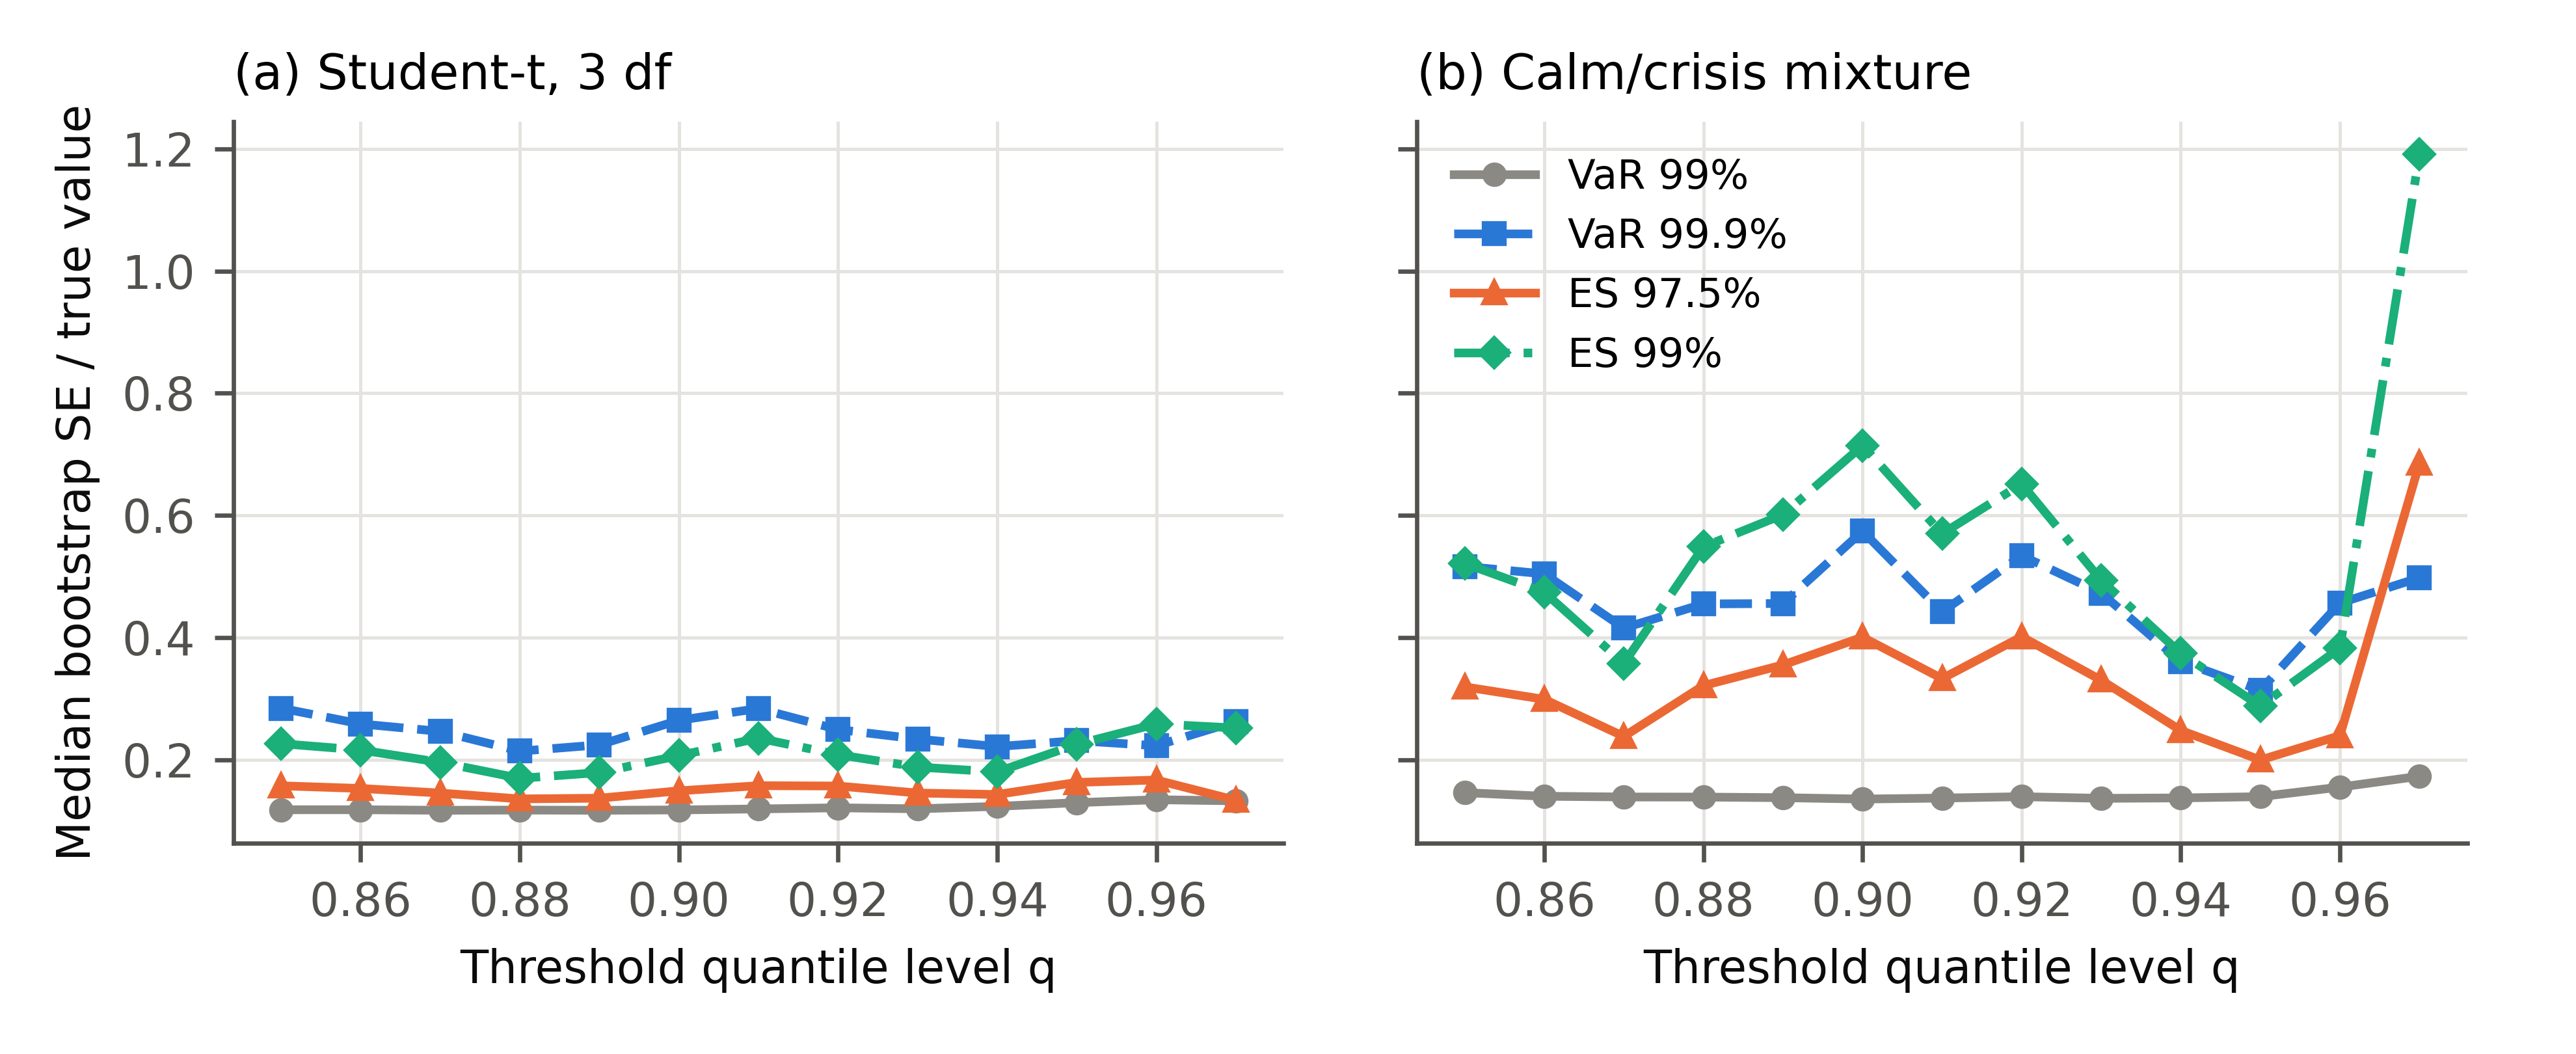

[2026-11-01 20:09:24] computed GPD_xi=0.2_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:09:24] stress GPD xi=0.2, n = 250: 100 samples
[2026-11-01 20:09:46] computed GPD_xi=0.5_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:09:46] stress GPD xi=0.5, n = 250: 100 samples
[2026-11-01 20:10:07] computed Student-t3_n250_R100_B100.csv in 0.3 min
[2026-11-01 20:10:07] stress Student-t3, n = 250: 100 samples
[2026-11-01 20:10:28] computed Student-t5_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:10:29] stress Student-t5, n = 250: 100 samples
[2026-11-01 20:10:50] computed Normal_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:10:50] stress Normal, n = 250: 100 samples
[2026-11-01 20:11:11] computed Regime_shuffled_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:11:11] stress Regime shuffled, n = 250: 100 samples
[2026-11-01 20:11:32] computed Regime_blocked_n250_R100_B100.csv in 0.4 min
[2026-11-01 20:11:32] stress Regime blocked, n = 250: 100 samples
[2026-11-01 20:11:54] computed GARCH(1,1)-t5_n250_R1

C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:107: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby("scenario").apply(rates).loc[[s for s in DESIGNS if s in set(d.scenario)]]


Table4_accuracy_by_target


,measure,label,rmse_cells,rmse_pooled,mae,under20,over100,wins_vs_ew
0,VaR 99%,Equal weights,16.29,18.21,9.53,11.54,0.25,0
1,VaR 99%,CV-BMA,16.37,18.28,9.68,12.17,0.25,10
2,VaR 99%,VPW (VaR 99%),16.28,18.19,9.45,11.50,0.25,12
3,VaR 99%,TPW,16.25,18.16,9.45,11.71,0.25,15
4,VaR 99.9%,Equal weights,53.12,76.64,20.62,26.96,4.67,0
5,VaR 99.9%,CV-BMA,65.33,95.97,21.20,25.71,6.21,3
6,VaR 99.9%,CV-BMA LOO+floor,45.37,53.94,21.13,29.46,4.50,14
7,VaR 99.9%,VPW (VaR 99%),44.29,52.12,20.82,28.00,3.92,16
8,VaR 99.9%,TPW-core,34.94,38.95,19.98,32.88,2.17,24
9,VaR 99.9%,TPW,35.00,38.99,20.03,32.88,2.21,24


Table5_ES975_n250


,Equal weights,CV-BMA,VPW (VaR 99%),TPW,TMV
"GPD, ξ = 0.2",40.16,29.81,33.97,21.33,18.99
"GPD, ξ = 0.5",171.02,279.06,159.86,71.61,60.66
"Student-t, 3 df",102.85,212.42,101.31,35.05,32.85
"Student-t, 5 df",18.19,19.19,18.31,16.86,16.57
Normal,8.41,8.46,8.42,8.43,8.44
"Regime, shuffled",1231.02,1583.23,1284.29,64.55,49.44
"Regime, blocked",134.38,1031.84,79.56,38.84,47.98
"GARCH(1,1)-t₅",39.09,62.15,37.98,35.54,35.39


... (6 outputs left out)

TableC2_exact_GPD_ES


ES97.5_ew  ES97.5_cv  ES97.5_vpw  ES97.5_tpw_core  ES97.5_tpw  ES99_ew  ES99_cv  ES99_tpw
xi   n                                                                                              
-0.2 1000       3.22       3.25        3.23             3.24        3.24     4.00     4.04      4.00
     5000       1.40       1.41        1.41             1.40        1.40     1.62     1.64      1.61
 0.0 1000       6.33       6.38        6.32             6.32        6.32     8.70     8.77      8.62
     5000       2.47       2.49        2.47             2.47        2.47     3.32     3.34      3.32
 0.2 1000      11.47      11.64       11.51            11.21       11.21    16.69    17.15     15.85
     5000       4.28       4.28        4.28             4.27        4.27     6.02     6.03      5.98
 0.5 1000     167.14     170.81      185.59            36.22       35.26   255.37   261.14     49.34
     5000      12.39      12.58       12.48            11.42       11.42    17.03    17.38     15.37

TableC3_bias_term_versions


,version,Stress: ES 97.5%,Stress: ES 99%,Exact GPD: ES 97.5%,Exact GPD: ES 99%
0,TPW-core,47.22,46.36,9.57,13.22
1,"Upper-half consensus, raw squared deviation",26.51,37.41,19.18,28.56
2,"Upper-half consensus, debiased",25.20,34.79,18.07,26.83
3,"Full-grid consensus, debiased (TPW)",24.97,33.32,9.45,13.01


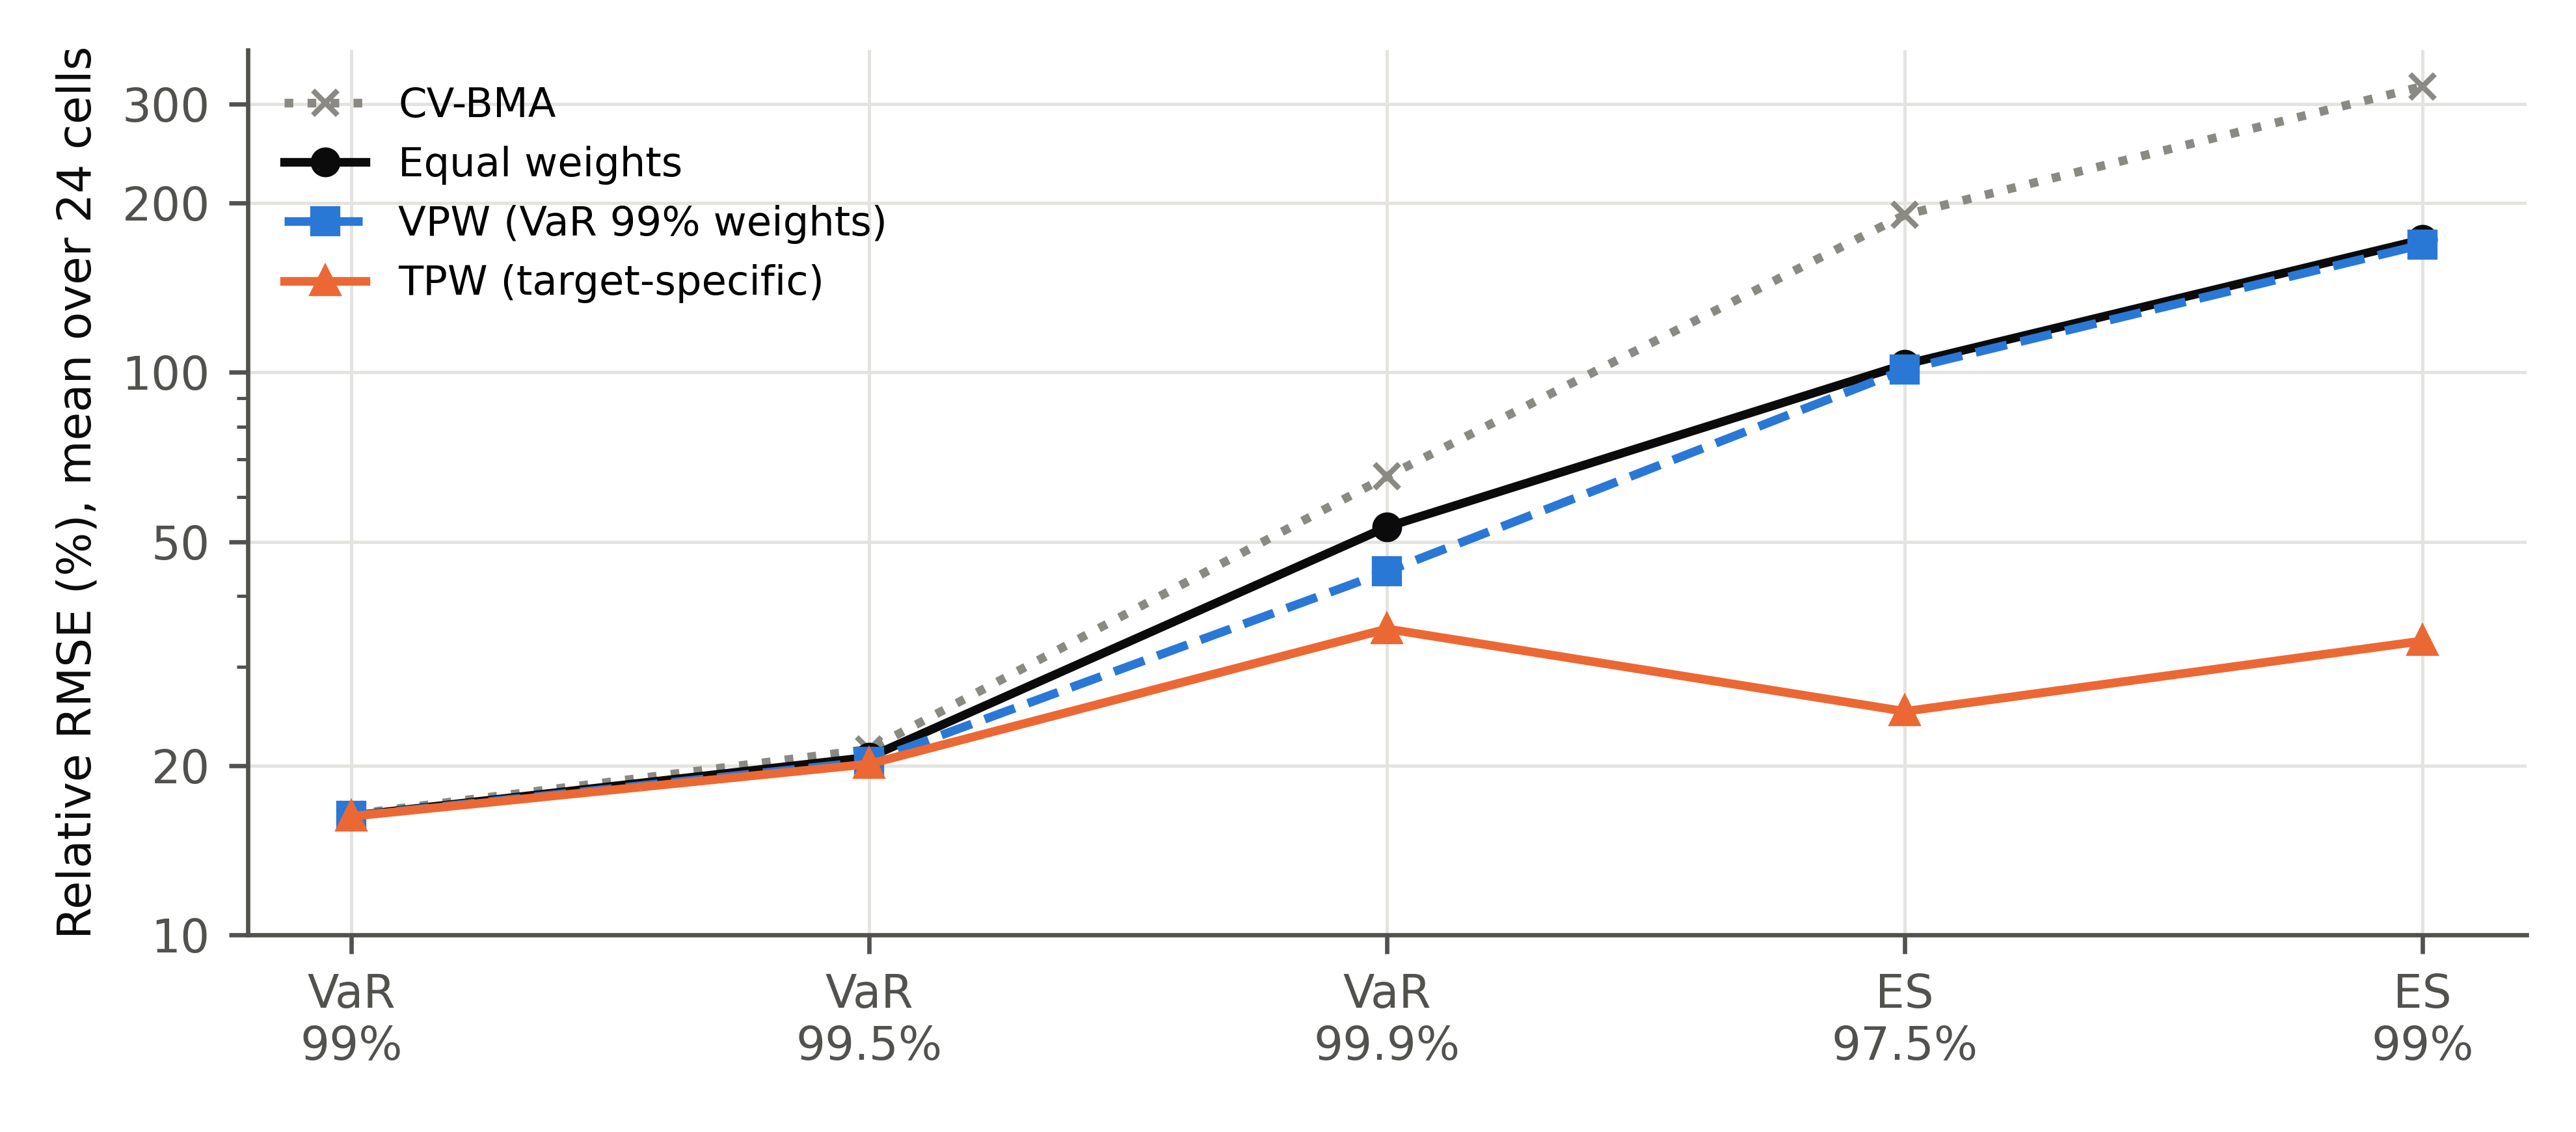

In [20]:
# ==========================================================================================
# CELL 18 - PART 1 - THEORY: Tables 1-3, Figure 1
# ==========================================================================================
th = part1_theory()
for k in ("Table1_asymptotic_dispersion", "Table2_explosion_probability", "Table3_finite_sample_dispersion"):
    print(k); display(th[k].round(3))
display(Image(filename=str(th["Figure1"]), width=700))

# ==========================================================================================
# CELL 19 - PART 2 - SIMULATION: Tables 4-6, C1-C3, Figure 2
# ==========================================================================================
sim = part2_simulation()
for k in ("Table4_accuracy_by_target", "Table5_ES975_n250", "Table6_shortfall_excess", "TableC1_failure_rates",
          "Reliability_Sections_4_1_and_5_2", "TableC2_exact_GPD_ES", "TableC3_bias_term_versions"):
    print(k); display(sim[k].round(2))
display(Image(filename=str(sim["Figure2"]), width=700))


In [ ]:
# ==========================================================================================
# CELL 20 - PART 3 - PUBLISHED RULES (R): Table 7
# ==========================================================================================
pub = part3_published_rules(stress=sim["_stress"], run_r=USER_RUN_R)
if pub:
    display(pub["Table7_published_rules"].round(2))
# ==========================================================================================
# CELL 21 - PART 4 - MARKET DATA: Tables 8-9
# ==========================================================================================
mk = part4_market()
for k, v in mk.items():
    print(k); display(v.round(3))
# ==========================================================================================
# CELL 22 - PART 5 - ROLLING ES BACKTESTS: Table C4 (slowest part)
# ==========================================================================================
bt = part5_backtests()
display(bt["TableC4_backtest_summary"].round(4))
# ==========================================================================================
# CELL 23 - PART 6 - DANISH FIRE LOSSES: Tables 10, C5, Figure 3
# ==========================================================================================
dn = part6_danish(run_r=USER_RUN_R)
print("Table 10"); display(dn["Table10_danish"].round(2))
print("Table C5"); display(dn["TableC5_danish_by_year"].round(1))
display(Image(filename=str(dn["Figure3"]), width=700))

# ==========================================================================================
# CELL 24 - PART 7 - INTEGRITY CHECKS AND MANIFEST
# ==========================================================================================
s = sim["_stress"]
checks = {"all simulation replications succeeded": bool(s["ok"].all()), "no warnings recorded": len(WARNINGS) == 0}
if RUN_MODE == "full":                                    # key numbers of the submitted paper
    t4 = sim["Table4_accuracy_by_target"].set_index(["measure", "label"])["rmse_cells"]
    for k, v in {("ES 97.5%", "Equal weights"): 103.31, ("ES 97.5%", "CV-BMA"): 190.52, ("ES 97.5%", "TPW"): 24.97,
                 ("ES 99%", "TPW"): 33.32, ("VaR 99.9%", "TPW"): 35.00}.items():
        checks[f"Table 4 {k[0]} {k[1]} = {v}"] = abs(t4[k] - v) < 0.006
    lam = sim["Table6_shortfall_excess"].set_index("target")["break_even_lambda"]
    checks["Table 6 break-even ES 97.5% = 22.7"] = abs(lam["ES 97.5%"] - 22.7) < 0.05
    c5 = dn["TableC5_danish_by_year"].set_index("Year")
    checks["Table C5 1980 TPW ES 99% = 202.1"] = abs(c5.loc["1980", "TPW"] - 202.1) < 0.05
display(pd.Series(checks, name="passed"))
if WARNINGS:
    print("\n".join(WARNINGS[-20:]))
print("manifest:", part7_finish())
print("tables:", table_dir()); print("figures:", figure_dir())

[2026-11-01 21:13:24] WARNING: Rscript not found - Table 7 / Northrop column of Table 10 skipped
[2026-11-01 21:13:24] Table 7 skipped: no results of R/published_rules.R
[2026-11-01 21:13:49] computed levels_B200.csv in 0.4 min
[2026-11-02 00:24:05] computed SandP_500_w250_s21_B100.csv in 190.3 min
[2026-11-02 00:24:05] windows S&P 500: 216
[2026-11-02 08:56:38] computed EURUSD_w250_s21_B100.csv in 512.6 min
[2026-11-02 08:56:39] windows EURUSD: 223
[2026-11-02 08:57:59] computed GOLD_w250_s21_B100.csv in 1.3 min
[2026-11-02 08:57:59] windows GOLD: 216
[2026-11-02 08:59:18] computed WTI_w250_s21_B100.csv in 1.3 min
[2026-11-02 08:59:18] windows WTI: 216
[2026-11-02 09:00:48] computed UST10Y_w250_s21_B100.csv in 1.5 min
[2026-11-02 09:00:48] windows UST10Y: 216
[2026-11-02 09:01:50] computed BTC_w250_s21_B100.csv in 1.1 min
[2026-11-02 09:01:50] windows BTC: 150


C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ch = 100 * M[m].pct_change().abs().dropna()
C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ch = 100 * M[m].pct_change().abs().dropna()
C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior

[2026-11-02 09:01:50] Saved outputs\tables\full\Table8_market_levels.csv


C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ch = 100 * M[m].pct_change().abs().dropna()
C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ch = 100 * M[m].pct_change().abs().dropna()
C:\Users\igwanani.EMPOWERBANK1\AppData\Local\Temp\ipykernel_25920\3415354274.py:211: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior

[2026-11-02 09:01:50] Saved outputs\tables\full\Table9_stressed_windows_ES99.csv
[2026-11-02 09:01:50] Saved outputs\tables\full\Table9b_stressed_windows_ES975.csv
[2026-11-02 09:01:50] Saved outputs\tables\full\Table9c_stressed_windows_VaR999.csv
[2026-11-02 09:01:50] Saved outputs\tables\full\Windows_largest_disagreement_ES975.csv
Table8_market_levels


,n,ES 97.5%: Equal weights,ES 97.5%: CV-BMA,ES 97.5%: TPW,ES 99%: Equal weights,ES 99%: CV-BMA,ES 99%: TPW,VaR 99.9%: Equal weights,VaR 99.9%: CV-BMA,VaR 99.9%: TPW,CV-BMA status,ES 99%: single threshold,ES 99%: range across thresholds (% of mean),VaR 99.9%: single threshold,VaR 99.9%: range across thresholds (% of mean)
sample,,,,,,,,,,,,,,,
"S&P 500, full sample",4780,4.003,4.001,4.003,5.416,5.405,5.415,7.669,7.637,7.664,ok,5.444,1.328,7.782,3.046
"S&P 500, financial crisis",632,6.373,6.448,6.365,8.153,8.575,8.034,10.780,11.995,10.201,collapse,7.906,8.328,9.650,21.776
"S&P 500, COVID year",253,7.799,7.799,7.702,10.803,10.803,10.306,15.570,15.570,14.215,fallback,12.230,20.160,18.489,30.922
"S&P 500, inflation",501,3.328,3.333,3.330,3.935,3.916,3.917,4.714,4.641,4.611,ok,NaN,4.048,NaN,12.893
EUR/USD,4926,1.848,1.848,1.848,2.510,2.514,2.502,3.594,3.602,3.574,ok,2.570,4.717,3.749,8.957
Gold,4774,3.290,3.295,3.290,4.191,4.182,4.188,5.558,5.512,5.539,ok,4.214,1.409,5.671,5.227
WTI crude oil,4776,7.616,7.625,7.615,10.293,10.410,10.261,14.650,14.988,14.548,ok,10.482,4.157,15.207,8.484
10-year Treasury note,4767,1.055,1.056,1.055,1.316,1.316,1.316,1.701,1.700,1.700,ok,1.316,0.405,1.705,0.970
Bitcoin,3391,10.979,10.988,10.979,14.170,14.187,14.170,18.987,19.012,18.966,ok,14.201,0.814,19.127,3.613


... (4 outputs left out)

Table9c_stressed_windows_VaR999


,series,windows,mean_abs_change_ew,changes_over_25pct_ew,mean_abs_change_cv,changes_over_25pct_cv,mean_abs_change_tpw,changes_over_25pct_tpw,tpw_vs_ew_level_pct,cv_fails_pct,cv_loo_fails
0,S&P 500,216,9.706,18,12.426,25,8.625,19,-3.154,53.704,0
1,EUR/USD,223,10.308,20,11.871,28,9.387,24,-5.453,57.848,1
2,Gold,216,10.021,18,12.272,24,7.187,15,-4.534,47.222,0
3,WTI crude oil,216,9.593,14,12.925,25,9.143,17,-3.150,60.648,0
4,10-year Treasury note,216,6.755,13,8.303,16,6.234,12,-2.366,48.148,0
5,Bitcoin,150,8.700,13,13.872,21,7.884,12,-5.331,31.333,2
6,All series,1237,9.213,96,11.841,139,8.094,99,NaN,50.849,3


Windows_largest_disagreement_ES975


,series,window_end,max/min,Equal weights,CV-BMA,TPW,CV-BMA status
0,S&P 500,2006-05-02,2.042,2.809,1.394,1.376,ok
1,S&P 500,2018-02-05,1.296,2.284,2.649,2.044,ok
2,S&P 500,2017-04-05,1.207,2.357,2.149,1.954,ok
3,EURUSD,2009-02-10,6.015,61.845,23.707,10.282,ok
4,EURUSD,2009-04-09,2.869,20.730,14.841,7.226,ok
5,EURUSD,2018-09-14,2.417,2.155,2.993,1.238,ok
6,GOLD,2020-08-17,3.568,10.911,12.961,3.633,ok
7,GOLD,2020-12-15,2.637,10.467,5.808,3.969,ok
8,GOLD,2020-04-17,2.096,3.664,6.987,3.334,collapse
9,WTI,2014-11-04,2.395,3.750,7.635,3.188,collapse
